# Predicting TFT Placement from Board Composition

**A Data Science case study on Teamfight Tactics ranked matches: from raw match data to an interpretable, temporally-validated placement model.**

### Table of contents

1. [Introduction](#1-introduction)
2. [The dataset](#2-the-dataset)
3. [Data quality & preprocessing](#3-data-quality--preprocessing)
4. [Exploratory data analysis](#4-exploratory-data-analysis)
5. [Composition archetypes](#5-composition-archetypes)
6. [Contest analysis](#6-contest-analysis)
7. [Feature engineering](#7-feature-engineering)
8. [Data leakage](#8-data-leakage)
9. [Machine learning model](#9-machine-learning-model)
10. [Evaluation](#10-evaluation)
11. [Concept drift & temporal validation](#11-concept-drift--temporal-validation)
12. [Explainability with SHAP](#12-explainability-with-shap)
13. [Error analysis](#13-error-analysis)
14. [Conclusions](#14-conclusions)

This notebook uses the pipeline already implemented in `src/` (ingestion, cleaning, feature
engineering, clustering, modeling, explainability).

## 1. Introduction

### Context

**Teamfight Tactics (TFT)** is an auto-battler: 8 players independently build a board of champions
(with traits and items) over ~35-40 rounds, fighting each other's boards automatically at fixed
intervals. Rounds are simultaneous: every player is drafting, itemizing and positioning against the
same shared pool of units and items, while combat outcomes depend on the board they've built, not
on direct control. A player's final result is a **placement from 1st (best) to 8th (worst)**,
determined by elimination order.

This makes placement prediction particularly difficult. Unlike a single-agent game, a board's strength
is not a fixed, absolute property: it depends on match-ups, timing (a board can be strong early and
fall off, or the reverse), and on how many other players in the same lobby are competing for the
same units and items ("contest", defined precisely in Section 6). A model that only looks at a
static final-board snapshot is missing all of that, which sets a realistic limit on how well
placement can be predicted from this data alone.

### Problem statement

Given a participant's **final board composition** (champions, star levels, items, active traits) and
match context (rank tier, patch), can we predict their **placement (1–8)**, and which parts of a
composition contribute most to that prediction? This is a retrospective, end-of-game prediction task:
the composition used as input is the one each player ended the game with, not one available at
draft time or mid-round. It is not a pre-game or mid-game forecasting model, and the results below
should not be read as "pick this comp and you'll place well" — see Section 9.1 for how this shapes
the modeling choice.

### Research questions

1. Can final board composition alone meaningfully predict placement better than a naive baseline?
2. Which features (traits, champions, items, economy) matter most, and in which direction?
3. Do players who share the same "archetype" (comp identity) hurt each other's placement when they
   land in the same lobby, i.e., is board strength in TFT relative, not absolute?
4. Does a model trained on early patches generalize to future patches, given TFT's frequent
   rebalancing (**concept drift**)?
5. Where does the model fail, and does that failure concentrate in specific archetypes, ranks or
   patches?

### Methodology overview

The notebook works through the pipeline in order, one step at a time, and each step only starts once
the one before it can be trusted.

First it checks the raw data: missing values, duplicates, contamination. Only once that's clean does
it look at the data itself, how placement is distributed, and whether rank or patch matter.

Next it groups boards into archetypes using clustering, then checks whether players who share the same
archetype hurt each other's placement.

Before training anything, it builds the feature matrix and checks it for data leakage, columns that
would let the model cheat by seeing the answer indirectly.

Then it trains a gradient-boosted regression model and evaluates it on a time-based split: training on
older patches, testing on newer ones, instead of mixing them randomly. This matters because the game
changes with every patch, and a random split could hide that.

The last part explains why the model predicts what it does (SHAP) and where it gets things wrong
(error analysis), then ties the results back to the five research questions from the introduction.


### Setup

Notebooks run from the repo root with `src/` added to
`sys.path`, so imports mirror how the pipeline scripts import each other (`from db import
get_engine`, not `from src.db import ...`). Chart styling matches the palette used throughout the
project's existing notebooks, for visual consistency.

In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from db import get_engine

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42

# Rank tiers in ascending skill order. MASTER_PLUS is a legacy label from before the
# Challenger/GM/Master split was tracked separately (a handful of early matches) - placed
# next to MASTER since that's what it represents.
TIER_ORDER = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD",
              "DIAMOND", "MASTER", "MASTER_PLUS", "GRANDMASTER", "CHALLENGER"]

# --- chart styling (same palette as the project's existing notebooks) ---
COLOR_BLUE = "#2a78d6"
COLOR_RED = "#e34948"
COLOR_GREEN = "#3f9142"
COLOR_MUTED = "#898781"
COLOR_GRID = "#e1e0d9"
COLOR_TEXT = "#0b0b0b"
COLOR_TEXT_SECONDARY = "#52514e"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": COLOR_MUTED,
    "axes.labelcolor": COLOR_TEXT_SECONDARY,
    "xtick.color": COLOR_MUTED,
    "ytick.color": COLOR_MUTED,
    "text.color": COLOR_TEXT,
    "font.size": 10,
    "grid.color": COLOR_GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

engine = get_engine()
print("Connected to", engine.url)

Connected to sqlite:///data/processed/tft.db


## 2. The dataset

### Origin and collection method

The data comes from the **Riot Games TFT API** and is collected by `src/ingest_matches.py`. There is no
API endpoint that simply lists all TFT matches, so the collection has to start from known players:

1. **Seed players** are taken from each rank tier. Challenger, Grandmaster and Master use their
   dedicated ladder endpoints, while Diamond down to Iron use the paginated league-entries endpoint
   (`src/riot_client.py`).
2. For each seed player, the pipeline fetches their **recent ranked match history** (match IDs followed
   by the full match details). Matches are then deduplicated across seed players, since several of
   them can have played in the same lobby.
3. Each match is filtered to **TFT Set 17, ranked solo queue only** (`queue_id == 1100`) and stored in
   a normalized SQLite schema (`matches`, `participants`, `participant_units`,
   `participant_unit_items`, `participant_traits`, `participant_augments`; see `src/db.py`).

One detail about the rank information is important: `seed_tier` records **the rank bucket of the seed
player used to find the match**. It is not a verified rank for all 8 players in that lobby. This is
only an approximation, and the implications are discussed in Section 3.

### Unit of observation

The unit of observation is the **participant**, meaning one player's result in one match. Each row
contains that player's final board, match context and placement. Since TFT matches have 8 players,
each match contributes exactly 8 participant rows.

### Scale, period and patches covered

The dataset contains **35,415 matches and 283,320 participant rows**, covering the period from
**2026-04-15 to 2026-08-13**. The 8-player structure is preserved in the data (8.0 participants per
match). This raw count includes a small share of non-player bot rows, corrected to 277,329 human
participants in Section 3.1.

The data covers **9 patches (16.8 → 16.16)**. The number of matches is not evenly distributed across
patches: 16.14 and especially 16.15 account for a large share of the dataset, while the earliest
patches have much less data. This matters later because the held-out test patches (16.15 and 16.16)
are not just a small sample of the dataset; 16.15 alone represents a substantial part of it.

### Variables available per participant

| Group | Fields |
|---|---|
| Outcome | `placement` (1-8, target), `win` |
| Context | `seed_tier`, `patch` (derived from `game_version`), `game_length` |
| Economy / timing | `level`, `gold_left`, `last_round`, `time_eliminated`, `players_eliminated`, `total_damage_to_players` |
| Composition | `units` (champion, star level `tier`, `rarity`, `itemNames`), `traits` (name, `num_units`, `style`, `tier_current`/`tier_total`) |
| Not available | `augments`. This field is completely absent from the raw API payload for this dataset, rather than simply being empty (verified against a raw payload in Section 3.4). |
### Known sampling biases

There are a few things to keep in mind when interpreting the dataset:

- **Ladder-seeded, not uniform-random.** Players are reached through the ranked ladder, so the sample
  mainly represents *active, ladder-visible* players. Someone who plays rarely, or who stopped playing
  before the ladder snapshot, is less likely to appear regardless of their actual skill.
- **Recent matches only.** The API returns each seed player's *N most recent* ranked matches. Since
  lower-tier players generally queue less often, their N-match window can cover a much longer period
  than that of a high-elo player who plays frequently. This creates a **tier/patch confound**, which is
  quantified in Section 3.
- **`seed_tier` is a match-level label.** It is a good approximation of the seed player's tier, but it
  is not verified for the other 7 participants in the lobby. Their ranks are not necessarily identical,
  even though ranked matchmaking generally keeps them relatively close together.


## 3. Data quality & preprocessing

This section audits the data for the kinds of problems that silently corrupt downstream analysis:
missing values, duplicates, structural contamination, and (found while writing this notebook) a
dtype bug in an intermediate CSV export. Two contamination issues were already found and fixed
earlier in the project's history (visible in `src/cleanup_matches.py` and the
`EXCLUDED_CHARACTER_IDS` filter in `src/features/build_feature_matrix.py`); I verify they're
actually clean in the current database rather than taking that on faith.

### 3.1 Missing values and structural integrity

In [2]:
missing = pd.DataFrame({
    "matches": pd.read_sql("SELECT * FROM matches LIMIT 200000", engine).isna().sum(),
}).query("matches > 0")
print("Columns in `matches` with any NULLs:")
print(missing if not missing.empty else "  none")

participants_df = pd.read_sql("SELECT * FROM participants", engine)
missing_p = participants_df.isna().sum()
missing_p = missing_p[missing_p > 0]
print("\nColumns in `participants` with any NULLs:")
print(missing_p if not missing_p.empty else "  none")

print(f"\nExactly 8 participants per match: "
      f"{(participants_df.groupby('match_id').size() == 8).all()}")

dup_mask = participants_df.duplicated(subset=["match_id", "puuid"], keep=False)
print(f"Duplicate participant rows (same match_id + puuid): "
      f"{participants_df.duplicated(subset=['match_id', 'puuid']).sum()}")
print(f"Placement values outside 1-8: "
      f"{((participants_df['placement'] < 1) | (participants_df['placement'] > 8)).sum()}")

# The duplicates above are not a real ingestion bug - check what puuid they share.
dup_puuids = sorted(participants_df.loc[dup_mask, "puuid"].unique())
print(f"\nDistinct puuid values involved in the duplicate rows: {dup_puuids}")

is_bot = participants_df["puuid"] == "BOT"
n_bots = int(is_bot.sum())
n_human_participants = int(len(participants_df) - n_bots)
print(f"Participant rows with puuid == 'BOT' (Riot's AI-fill placeholder): {n_bots:,} "
      f"across {participants_df.loc[is_bot, 'match_id'].nunique():,} matches")
print(f"Human participants once bots are excluded: {n_human_participants:,}")

bot_tier = pd.read_sql(
    "SELECT m.seed_tier, COUNT(*) AS bot_rows "
    "FROM participants p JOIN matches m ON m.match_id = p.match_id "
    "WHERE p.puuid = 'BOT' GROUP BY m.seed_tier ORDER BY bot_rows DESC",
    engine,
)
print("\nBot rows by seed_tier:")
print(bot_tier.to_string(index=False))


Columns in `matches` with any NULLs:
  none



Columns in `participants` with any NULLs:
  none

Exactly 8 participants per match: True


Duplicate participant rows (same match_id + puuid): 3909
Placement values outside 1-8: 0

Distinct puuid values involved in the duplicate rows: ['BOT']
Participant rows with puuid == 'BOT' (Riot's AI-fill placeholder): 5,991 across 2,082 matches
Human participants once bots are excluded: 277,329

Bot rows by seed_tier:
seed_tier  bot_rows
   BRONZE      1925
   SILVER      1849
     IRON      1478
     GOLD       727
 PLATINUM        12


Missing values, the 8-per-match invariant, and the placement range are all clean. The one number that
isn't clean at first glance is the duplicate count above: **3,909 rows** share a `(match_id, puuid)`
pair, which on its face contradicts "no duplicates." Rather than wave that away, `dup_puuids` shows the
duplicated rows all share exactly one `puuid` value: `'BOT'`, Riot's placeholder identity for the AI
opponents it fills into a lobby when a queue doesn't have 8 real players waiting. These aren't ingestion
duplicates at all; they're distinct AI participants that happen to share a literal string instead of a
real account ID.

That makes them worth quantifying properly: they aren't a labeling curiosity, they're
non-player rows sitting inside a dataset whose whole premise is human decision-making.
**5,991 bot participant rows across 2,082 matches** (2.1% of all participants), concentrated almost
entirely in the lowest tiers (**Bronze 1,925, Silver 1,849, Iron 1,478, Gold 727**, a residual 12 in
Platinum, essentially none above). A bot's board is not a strategic choice: it has no place in a
composition-vs-placement model, an archetype clustering, or a tier-level pick-rate comparison.

**Fix:** `load_base()` (`src/features/build_feature_matrix.py`) and every loader in
`src/analysis/tier_comparison.py` now filter `puuid != 'BOT'` at the SQL level, so
`feature_matrix.csv`, `archetype_clusters.csv`, and every trait/champion/archetype pick-rate table used
from Section 4 onward in this notebook already exclude them. The patch dtype bug (Section 3.6) was
flagged but deliberately left unfixed in `src/` because it didn't change any conclusion. Bot
contamination was different: it measurably distorted a headline finding (Sections 4.2, 5.4, 13.4),
so it's fixed at the source. `n_human_participants` (277,329) is the corrected population size used
as the pick-rate denominator from here on; `n_participants` (283,320) remains the raw count actually
returned by the API.

### 3.2 Queue contamination (already fixed upstream)


In [3]:
queue_check = pd.read_sql(
    "SELECT tft_set_number, queue_id, COUNT(*) AS n FROM matches GROUP BY tft_set_number, queue_id",
    engine,
)
queue_check

,tft_set_number,queue_id,n
0,17,1100,35415


A single row, set 17 / queue 1100 only, the cleanup is effective and there is no residual queue
contamination in the current database.

### 3.3 Non-player units excluded from composition features

Early cluster inspection (documented in the project's commit history) surfaced entries that made no
sense as champion picks: `TFT17_Enemy_Aatrox`, `TFT17_PVE_ElderDragon`, `TFT17_IvernMinion`,
`tft17_bardfollower`, `TFT17_Summon`, automatic companion/encounter units that leak into the raw
`units` payload, not actual player picks. `build_feature_matrix.py` excludes them via
`EXCLUDED_CHARACTER_IDS`. Confirming none of them reach the stored `participant_units` table isn't
possible (they're filtered at feature-build time, not ingestion time), instead I confirm the filter
is doing something real, i.e. these IDs do appear in the raw table and would otherwise pollute the
composition features:

In [4]:
from features.build_feature_matrix import EXCLUDED_CHARACTER_IDS

id_list = ", ".join(f"'{c}'" for c in EXCLUDED_CHARACTER_IDS)
query = ("SELECT character_id, COUNT(*) AS n FROM participant_units "
         "WHERE character_id IN (" + id_list + ") GROUP BY character_id")
excluded_counts = pd.read_sql(query, engine)
excluded_counts

,character_id,n
0,TFT17_Enemy_Aatrox,114
1,TFT17_IvernMinion,68021
2,TFT17_PVE_ElderDragon,1814
3,TFT17_Summon,43899
4,tft17_bardfollower,940


### 3.4 Augments: confirmed absent, not a parsing bug

`participant_augments` is empty for every participant. Before treating that as a limitation to
report rather than a bug to fix, I checked a raw API payload directly:

In [5]:
import json
import glob

augments_present = pd.read_sql("SELECT COUNT(*) AS n FROM participant_augments", engine)["n"].iloc[0]
print(f"Rows in participant_augments: {augments_present}")

sample_path = glob.glob("data/raw/*.json")[0]
sample_participant = json.load(open(sample_path, encoding="utf-8"))["info"]["participants"][0]
print(f"\nKeys present on a raw participant object ({Path(sample_path).name}):")
print(sorted(sample_participant.keys()))
print(f"\n'augments' key present: {'augments' in sample_participant}")

Rows in participant_augments: 0

Keys present on a raw participant object (EUN1_3792547133.json):
['companion', 'gold_left', 'last_round', 'level', 'missions', 'placement', 'players_eliminated', 'puuid', 'riotIdGameName', 'riotIdTagline', 'time_eliminated', 'total_damage_to_players', 'traits', 'units', 'win']

'augments' key present: False


The `augments` key is absent from the raw payload itself, this is an API/data availability
limitation for this dataset, not a parsing error. **Augments (a major TFT mechanic) cannot be used
as a feature or explanatory factor anywhere in this project.** This is carried forward as an explicit
limitation in Section 14.

### 3.5 The tier / patch confound

Because low-tier players queue less often, their "N most recent matches" window reaches much further
back in time than an active high-elo player's. This partially confounds `seed_tier` with `patch`:

In [6]:
tier_patch_range = pd.read_sql('''
    SELECT seed_tier,
           date(MIN(game_datetime)/1000, 'unixepoch') AS earliest,
           date(MAX(game_datetime)/1000, 'unixepoch') AS latest,
           COUNT(*) AS matches
    FROM matches
    GROUP BY seed_tier
    ORDER BY matches DESC
''', engine)
tier_patch_range

,seed_tier,earliest,latest,matches
0,DIAMOND,2026-04-24,2026-08-13,5233
1,EMERALD,2026-04-19,2026-08-13,5005
2,PLATINUM,2026-04-18,2026-08-13,4842
3,GOLD,2026-04-15,2026-08-13,4367
4,MASTER,2026-06-22,2026-08-13,3821
5,SILVER,2026-04-15,2026-08-13,3267
6,MASTER_PLUS,2026-07-14,2026-08-12,3036
7,GRANDMASTER,2026-07-01,2026-08-13,2127
8,BRONZE,2026-04-15,2026-08-13,1636
9,IRON,2026-04-15,2026-08-13,1215


Challenger's window is a single day; Iron/Bronze/Silver stretch back to mid-April. A naive
"placement by tier" comparison would therefore partly be comparing *different eras of the game's
balance*, and only partly a skill difference. `patch` is therefore kept as an explicit model
feature (Section 7), and the model is evaluated with a **time-based** split (Section 11).
Restricting collection to one narrow window was not a real option: Challenger's single day would
leave far too little data, and restricting everyone to Challenger's window would defeat the purpose
of comparing tiers at all.

### 3.6 A dtype bug found while writing this notebook

`src/features/build_feature_matrix.py` writes `patch` as a string ("16.10", "16.8", ...) into
`data/processed/feature_matrix.csv`. Reading that CSV back with plain `pd.read_csv`, with no dtype
hint, is where the problem starts:

In [7]:
FEATURE_MATRIX_PATH = "data/processed/feature_matrix.csv"

buggy = pd.read_csv(FEATURE_MATRIX_PATH, usecols=["patch"])
print("dtype inferred by plain pd.read_csv():", buggy["patch"].dtype)
print("unique values:", sorted(buggy["patch"].unique()))
print("as strings:   ", sorted(buggy["patch"].astype(str).unique()))

dtype inferred by plain pd.read_csv(): float64
unique values: [np.float64(16.1), np.float64(16.11), np.float64(16.12), np.float64(16.13), np.float64(16.14), np.float64(16.15), np.float64(16.16), np.float64(16.8), np.float64(16.9)]
as strings:    ['16.1', '16.11', '16.12', '16.13', '16.14', '16.15', '16.16', '16.8', '16.9']


Every value in the `patch` column looks like a valid decimal number, so pandas silently infers
`float64`. As a float, `"16.10"` and `"16.1"` are indistinguishable, Python has no way to keep a
"trailing zero" on a float, so **patch 16.10 is silently relabeled `16.1`** the moment it's read
back from the CSV. There's no true collision here (no patch is actually named "16.1"), but it does
break chronological sorting: sorted *as numbers*, `16.1 < 16.11 < ... < 16.16 < 16.8 < 16.9`, which
is not the game's actual patch order (16.8 → 16.9 → 16.10 → 16.11 → ... → 16.16).

**Practical impact:** `src/modeling/train_model.py` filters the test set with
`df["patch"].astype(str).isin({"16.15", "16.16"})`, those two values happen to round-trip correctly
(`16.15` and `16.16` already have two significant decimal digits), so **the train/test split itself
is unaffected**, and the model's `HistGradientBoostingRegressor` treats `patch` as a true categorical
feature (unordered partitioning), so **predictive performance is not affected either**. What *is*
affected is anything that displays or sorts patches chronologically downstream of a plain CSV read,
concretely, patch 16.10 would be mislabeled and mis-ordered in any chart or printed table built that
way. I fix this locally wherever the notebook loads the feature matrix from disk:

In [8]:
from modeling.train_model import patch_sort_key

fixed = pd.read_csv(FEATURE_MATRIX_PATH, usecols=["patch"], dtype={"patch": str})
print("dtype with dtype={'patch': str}:", fixed["patch"].dtype)
print("unique values:", sorted(fixed["patch"].unique(), key=patch_sort_key))

dtype with dtype={'patch': str}: object
unique values: ['16.8', '16.9', '16.10', '16.11', '16.12', '16.13', '16.14', '16.15', '16.16']


I'm not silently rewriting `src/features/build_feature_matrix.py` or `src/modeling/train_model.py`
for this, the fix belongs at the source (write patch pre-formatted, or have every downstream reader
pass `dtype={"patch": str}`), and I'm flagging it here rather than changing the pipeline's
methodology mid-notebook. In this notebook, every place that reads `feature_matrix.csv` from disk
uses `dtype={"patch": str}`, and Section 9 re-attaches the corrected patch labels onto the model's
train/test frames for reporting, since `load_and_prepare()` itself does the plain, unguarded read.

### 3.7 Distributions and outliers (a first look)

A quick sanity pass on the numeric columns before using any of them:

In [9]:
from features.build_feature_matrix import load_base

# load_base() computes `patch` fresh from game_version via regex, so unlike the CSV
# written to disk later (Section 3), this is not affected by any CSV round-trip dtype issue.
base = load_base(engine)

patch_overview = base.groupby("patch").agg(
    participants=("participant_id", "count"),
    matches=("match_id", "nunique"),
).reset_index()


def patch_sort_key(p):
    return tuple(int(x) for x in str(p).split("."))


patch_overview = patch_overview.sort_values("patch", key=lambda s: s.map(patch_sort_key))
patch_overview

,patch,participants,matches
7,16.8,22496,2934
8,16.9,16122,2146
0,16.10,18769,2444
1,16.11,15568,2023
2,16.12,15494,1997
3,16.13,30621,3912
4,16.14,56057,7083
5,16.15,85800,10816
6,16.16,16402,2060


In [10]:
numeric_summary = base[[
    "placement", "level", "gold_left", "last_round",
    "players_eliminated", "time_eliminated", "total_damage_to_players",
]].describe().T
numeric_summary

,count,mean,std,min,25%,50%,75%,max
placement,277329.0,4.463558,2.290880,1.0,2.000000,4.00000,6.000000,8.000000
level,277329.0,8.353998,0.953126,1.0,8.000000,8.00000,9.000000,10.000000
gold_left,277329.0,10.277360,18.086438,0.0,1.000000,2.00000,12.000000,225.000000
last_round,277329.0,31.481165,4.724322,0.0,28.000000,31.00000,35.000000,47.000000
players_eliminated,277329.0,0.800400,1.097708,0.0,0.000000,0.00000,1.000000,7.000000
time_eliminated,277329.0,1819.311205,261.497558,0.0,1637.320435,1825.92688,2014.022461,2698.680664
total_damage_to_players,277329.0,101.599032,70.508184,0.0,62.000000,94.00000,136.000000,10241.000000


Nothing structurally alarming: `placement` spans exactly 1-8 as expected, `level` maxes out at 10
(the set's level cap), `last_round`/`time_eliminated` look like plausible game-length figures. The
main thing worth flagging is `total_damage_to_players`, whose max (in the thousands) is far above
its median (double digits), a long right tail, plausible for a stat that accumulates over an entire
game for a player who wins many fights, but worth remembering it's a skewed variable rather than
treating its mean as a "typical" value.

## 4. Exploratory data analysis

The data-quality pass confirmed the dataset is structurally sound. Before building any features or
models, this section looks at what the data actually says: how placement is distributed, whether
rank tier and patch behave the way they should given what Section 3 already found about their
confound, and which traits/champions dominate at a raw pick-rate level.

### 4.1 Placement distribution

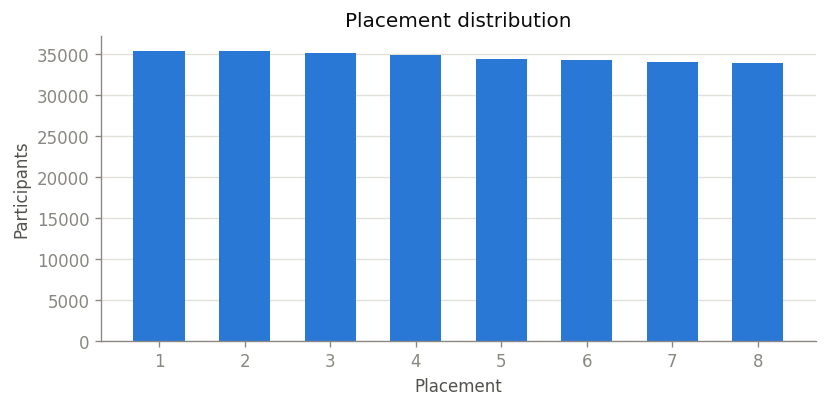

placement
1    35419
2    35315
3    35149
4    34836
5    34412
6    34279
7    34052
8    33867


In [11]:
placement_dist = base["placement"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(placement_dist.index, placement_dist.values, color=COLOR_BLUE, width=0.6)
ax.set_xticks(range(1, 9))
ax.set_xlabel("Placement")
ax.set_ylabel("Participants")
ax.set_title("Placement distribution")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

print(placement_dist.to_string())

**Not quite perfectly uniform anymore**, and that's expected, not a red flag. Placement counts step
down monotonically from 35,419 (1st) to 33,867 (8th) instead of landing on exactly `n_matches` each.
This is the direct, visible fingerprint of Section 3's bot exclusion: bots place worse than humans on
average, so removing them removes disproportionately more rows at the high-numbered (worse) placements
than at the low-numbered (better) ones, for the 2,082 matches that had a bot in them. The **shape** of
the imbalance, a steady decline from 1st to 8th, not a random scatter, is itself a sanity check that
the exclusion behaved exactly as expected, the same kind of "does the mechanism actually explain the
residual" reasoning the dtype-bug check in 3.6 relies on.

The practical consequence: **"average placement is mathematically ~4.5" is only still exact for
subgroups built from matches with zero bots in them.** For a subgroup like "all Diamond matches" that
holds (Diamond has essentially no bots, Section 3.1), but it quietly breaks down for the low tiers
where bots concentrate, which the next chart runs into directly.

### 4.2 Placement by rank tier, does `seed_tier` actually separate anything?


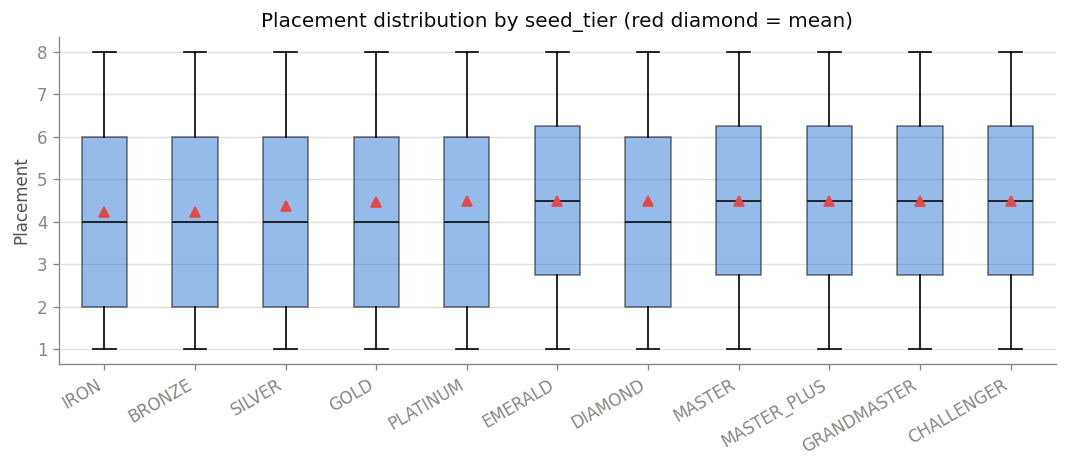

seed_tier
IRON           4.229
BRONZE         4.220
SILVER         4.363
GOLD           4.460
PLATINUM       4.499
EMERALD        4.500
DIAMOND        4.499
MASTER         4.500
MASTER_PLUS    4.500
GRANDMASTER    4.500
CHALLENGER     4.500
Name: placement, dtype: float64

In [12]:
tier_data = [base.loc[base["seed_tier"] == t, "placement"].values
             for t in TIER_ORDER if t in base["seed_tier"].unique()]
tier_labels = [t for t in TIER_ORDER if t in base["seed_tier"].unique()]

fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot(tier_data, tick_labels=tier_labels, patch_artist=True, showmeans=True,
                 medianprops={"color": COLOR_TEXT}, meanprops={"markerfacecolor": COLOR_RED, "markeredgecolor": COLOR_RED})
for patch in bp["boxes"]:
    patch.set_facecolor(COLOR_BLUE)
    patch.set_alpha(0.5)
ax.set_ylabel("Placement")
ax.set_title("Placement distribution by seed_tier (red diamond = mean)")
ax.grid(axis="y")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

base.groupby("seed_tier")["placement"].mean().reindex(TIER_ORDER).dropna().round(3)

Platinum and above still sit essentially exactly at 4.5 (Platinum 4.499 through Master+ 4.500),
those tiers have next to no bots, so the "grouping
whole matches, so it averages to 4.5" argument still holds for them, unchanged from before.

**Iron through Gold no longer sit at 4.5, and that gap is not a skill signal.** IRON averages 4.229,
BRONZE 4.220, SILVER 4.363, GOLD 4.460, a gradient that tracks almost exactly how bot-heavy each tier
is (roughly 15% of Iron's and Bronze's raw participant rows are bots, ~7% of Silver's, ~2% of Gold's).
The mechanism is the one flagged in Section 4.1: a match's 8 placements sum to 36 by construction, so
removing a below-average finisher (bots average placement 6.2, well worse than 4.5) from a match
necessarily pulls the *remaining* humans' average *below* 4.5. The more bots a tier's matches carry,
the further its human-only average drifts from 4.5, **in the direction that looks like "better
placement,"** even though nothing about how humans in that tier actually play has changed. Reading
Iron's 4.229 as "Iron players place better than Diamond players" would be exactly the same category of
mistake this section already warns against, just via a different mechanical route than the original
one.

Everything else about the original point stands: this chart still cannot isolate genuine skill-by-tier,
and what rank tier *can* still meaningfully correlate with is *composition* (which comps are played)
and, as tested rigorously in Section 12, *a small conditional shift in predicted placement once the
board itself is held fixed*.

### 4.3 Placement and volume by patch


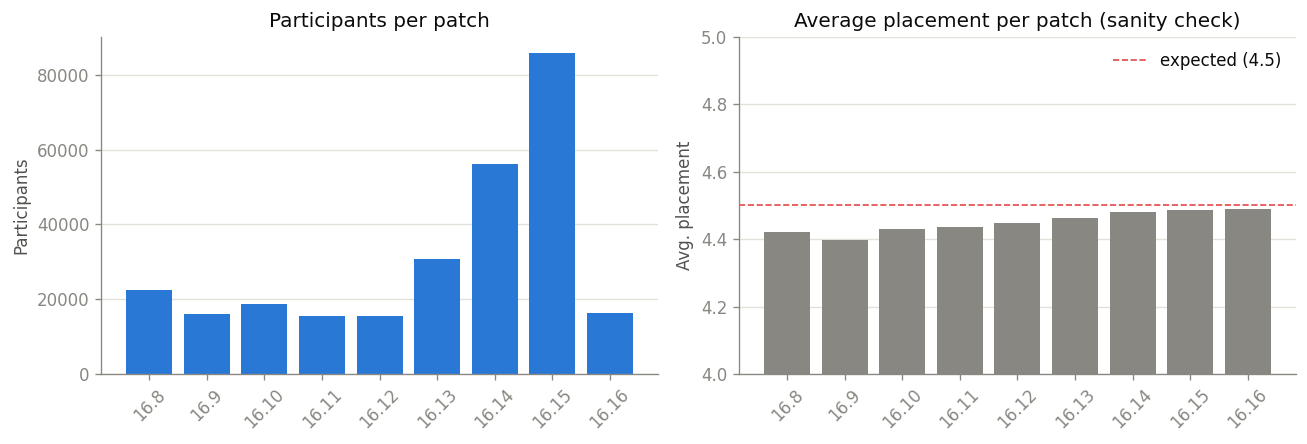

In [13]:
patch_stats = base.groupby("patch").agg(
    participants=("participant_id", "count"),
    avg_placement=("placement", "mean"),
).reindex(patch_overview.sort_values("patch", key=lambda s: s.map(patch_sort_key))["patch"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].bar(patch_stats.index, patch_stats["participants"], color=COLOR_BLUE)
axes[0].set_title("Participants per patch")
axes[0].set_ylabel("Participants")
axes[0].grid(axis="y")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(patch_stats.index, patch_stats["avg_placement"], color=COLOR_MUTED)
axes[1].axhline(4.5, color=COLOR_RED, linestyle="--", linewidth=1, label="expected (4.5)")
axes[1].set_ylim(4.0, 5.0)
axes[1].set_title("Average placement per patch (sanity check)")
axes[1].set_ylabel("Avg. placement")
axes[1].grid(axis="y")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

Volume is heavily skewed toward later patches (consistent with Section 2, the API surfaces recent
matches, so older patches are only reachable through players who happened to still have them in
their recent history). Average placement per patch is *close to* but no longer exactly 4.5
everywhere: it ranges from 4.397 (16.9) up to 4.491 (16.16), for the same mechanical reason as
4.2 — the tier/patch confound (Section 3.5) showing up again through the bot channel. Early patches
(16.8/16.9) draw more heavily on the low-tier participants whose "N most recent matches" window
reaches furthest back, and low tiers are exactly where bots concentrate, so early patches inherit
more of the same downward pull toward "looks better than 4.5" seen in Section 4.2. The game itself
didn't play differently on those patches. This is a useful second confirmation that nothing about
the patch grouping is silently distorted beyond that already-known mechanism — in particular, that
Section 3.6's patch dtype bug isn't quietly duplicating or dropping rows here (`base` was built
directly from SQL, not from the buggy CSV).

### 4.4 Which traits and champions actually get played?


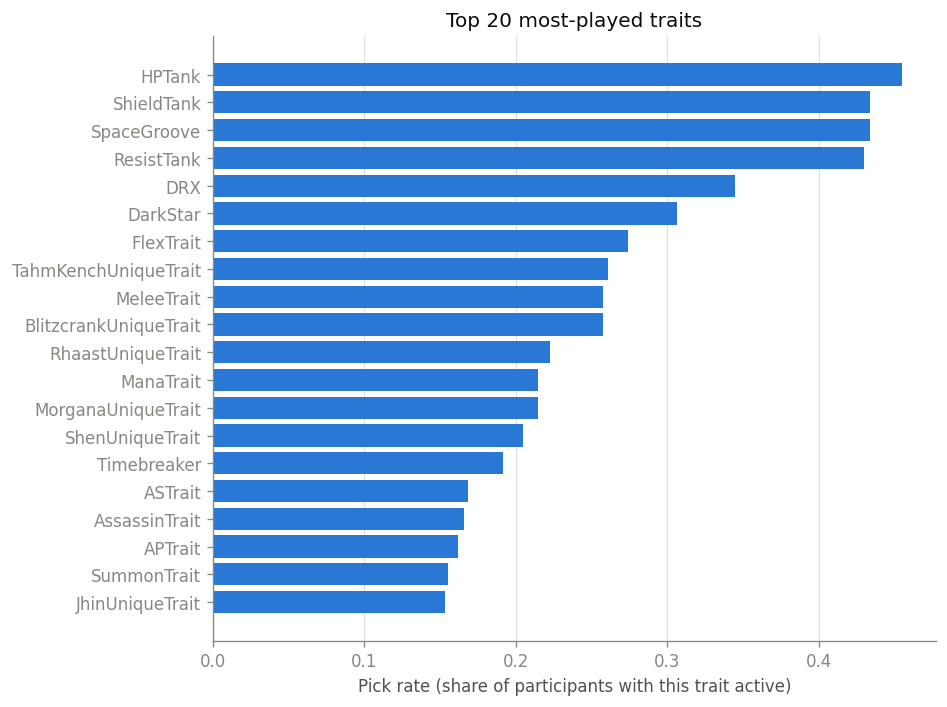

In [14]:
from analysis.tier_comparison import load_active_traits

traits_all = load_active_traits(engine).drop_duplicates(subset=["participant_id", "trait_name"])
trait_pickrate = (
    traits_all.groupby("trait_name")
    .agg(picks=("participant_id", "count"), avg_placement=("placement", "mean"))
    .assign(pick_rate=lambda d: d["picks"] / n_human_participants)
    .sort_values("pick_rate", ascending=False)
)

top_traits = trait_pickrate.head(20).sort_values("pick_rate")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([t.replace("TFT17_", "") for t in top_traits.index], top_traits["pick_rate"], color=COLOR_BLUE)
ax.set_xlabel("Pick rate (share of participants with this trait active)")
ax.set_title("Top 20 most-played traits")
ax.grid(axis="x")
plt.tight_layout()
plt.show()


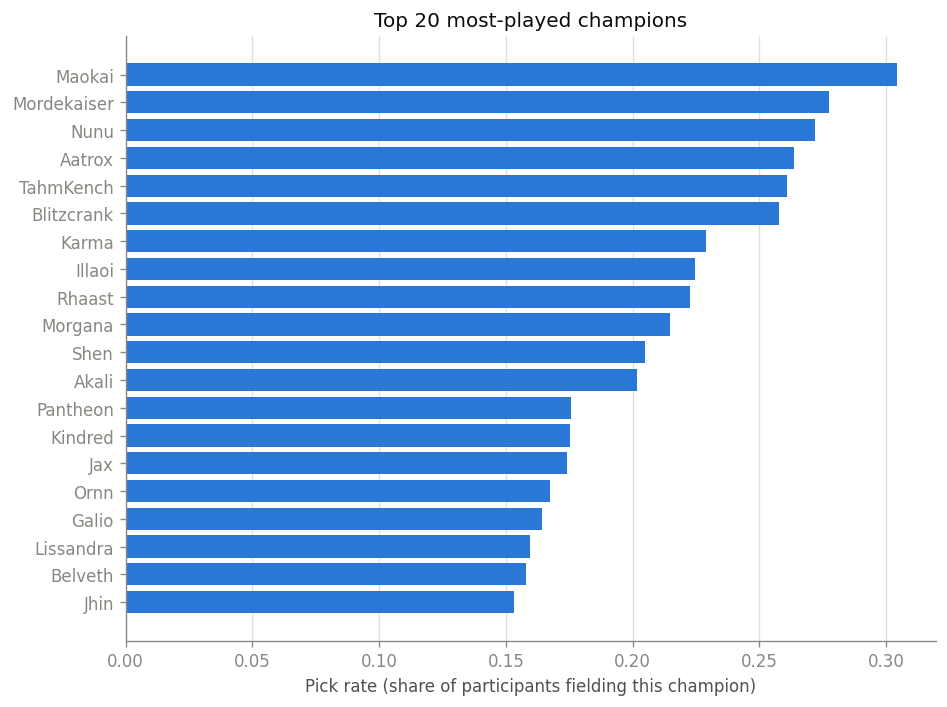

In [15]:
champs_all = pd.read_sql("""
    SELECT p.id AS participant_id, p.placement, u.character_id, u.tier
    FROM participant_units u
    JOIN participants p ON p.id = u.participant_id
    WHERE p.puuid != 'BOT'
""", engine)
champs_all = champs_all[~champs_all["character_id"].isin(EXCLUDED_CHARACTER_IDS)]

champ_pickrate = (
    champs_all.groupby("character_id")
    .agg(picks=("participant_id", "nunique"), avg_star=("tier", "mean"), avg_placement=("placement", "mean"))
    .assign(pick_rate=lambda d: d["picks"] / n_human_participants)
    .sort_values("pick_rate", ascending=False)
)

top_champs = champ_pickrate.head(20).sort_values("pick_rate")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([c.replace("TFT17_", "") for c in top_champs.index], top_champs["pick_rate"], color=COLOR_BLUE)
ax.set_xlabel("Pick rate (share of participants fielding this champion)")
ax.set_title("Top 20 most-played champions")
ax.grid(axis="x")
plt.tight_layout()
plt.show()


Individual pick rate is a first, crude signal of "meta relevance", high pick rate means a trait or
champion is commonly accessible/strong enough to include, but says nothing yet about whether it's
actually *good* for placement, or just common because it's cheap and flexible. That distinction is
picked up properly at the whole-composition level in Section 5 (archetypes), and at the individual
feature level via SHAP in Section 12.

### 4.5 Correlation of numeric context features with placement

A first look at which numeric columns move together with the outcome, this doubles as groundwork
for the leakage discussion in Section 8, since some of these correlations turn out to be dangerously
strong.

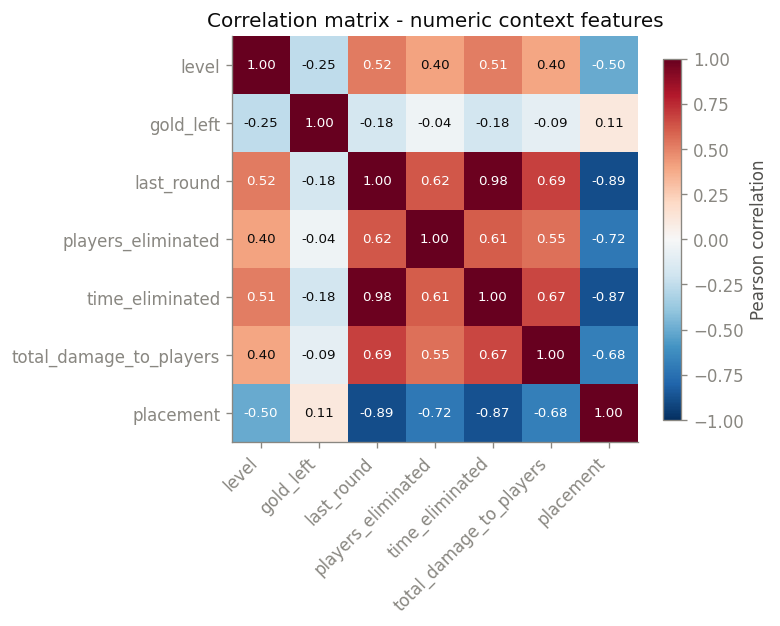

In [16]:
numeric_cols = ["level", "gold_left", "last_round", "players_eliminated",
                "time_eliminated", "total_damage_to_players", "placement"]
corr = base[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_cols)))
ax.set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.values[i, j]) > 0.5 else COLOR_TEXT, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation matrix - numeric context features")
plt.tight_layout()
plt.show()

`last_round`, `time_eliminated`, `players_eliminated` and `total_damage_to_players` all correlate
very strongly with `placement` (in the 0.5–0.9 range), far stronger than any composition feature is
likely to. That's expected once you know how these columns are computed: in TFT, placement *is*
elimination order, so a column that records elimination timing is close to restating the target
rather than explaining it. `gold_left` and `level` correlate much more weakly. This EDA finding is
picked up and acted on formally in Section 8.

## 5. Composition archetypes

Individual trait/champion pick rates (Section 4.4) can't tell a trait played as the backbone of a
strategy from the same trait picked as filler in a completely different comp. To reason about
"comps" the way a player would, as coherent wholes, participants need to be grouped by the actual
combination of pieces on their board. `src/analysis/archetypes.py` does this with **K-Means
clustering on binarized composition**.

### 5.1 Which variables, and why

The clustering input is **presence/absence of each trait and champion** (`(value > 0).astype(int)`),
not their tier/star level or item count. This is a deliberate choice: archetype *identity* is about
**which pieces are on the board**, not how far a given game happened to progress, two players who
both built a Blitzcrank/Vex/Fiora board are "the same archetype" whether one hit 3-star Blitzcrank
and the other only 2-star. Star levels and items are legitimate signals of *execution quality within
an archetype*, which is a different question, addressed separately in Section 5.3 (power curve) and
Section 12 (SHAP) rather than folded into the grouping itself.

In [17]:
from analysis.archetypes import load_composition_matrix, scan_k, fit_final, describe_cluster, K_CANDIDATES

comp_df, X_comp, comp_cols = load_composition_matrix()
n_traits = sum(c.startswith("trait__") for c in comp_cols)
n_champs = sum(c.startswith("champ__") for c in comp_cols)
print(f"{len(X_comp):,} participants, {len(comp_cols)} composition columns "
      f"({n_traits} traits, {n_champs} champions), binarized to presence/absence")

277,329 participants, 103 composition columns (41 traits, 62 champions), binarized to presence/absence


### 5.2 Choosing k

`k` is chosen by scanning candidate values on a 15,000-row sample and comparing **inertia**
(within-cluster sum of squares, always decreases with k, useful for spotting an elbow) against
**silhouette score** (how well-separated clusters are, from -1 to 1, not just monotonic with k, so
it can actually indicate a good stopping point).

  k= 8  inertia=  110026.6  silhouette=0.1736


  k=10  inertia=  103345.0  silhouette=0.1678


  k=12  inertia=   97068.9  silhouette=0.1666


  k=15  inertia=   89338.4  silhouette=0.1917


  k=18  inertia=   84189.4  silhouette=0.1958


  k=22  inertia=   77763.0  silhouette=0.2028


  k=26  inertia=   73577.8  silhouette=0.2107


  k=30  inertia=   71008.9  silhouette=0.2055


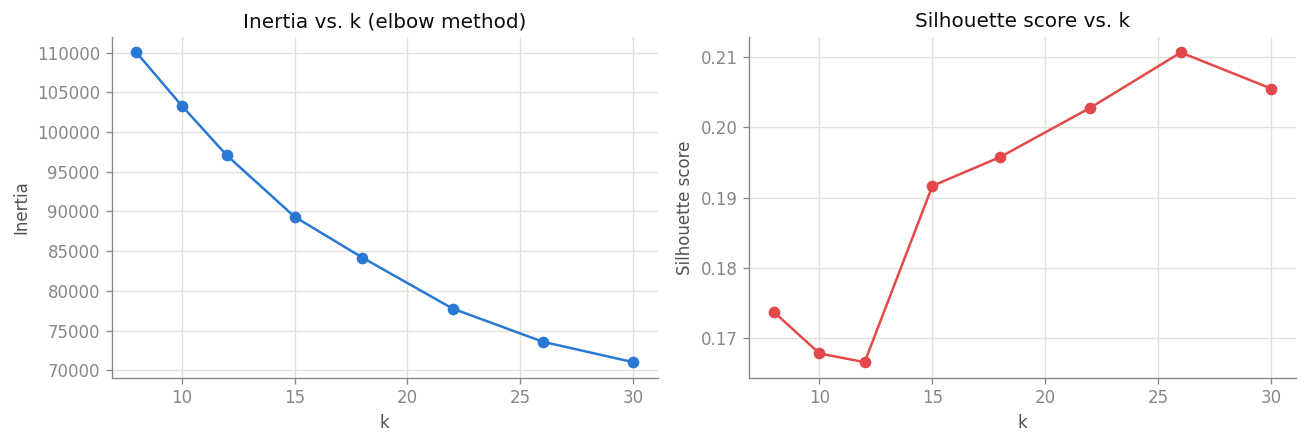

,k,inertia,silhouette
0,8,110026.575702,0.173647
1,10,103345.005233,0.167800
2,12,97068.853128,0.166557
3,15,89338.394259,0.191657
4,18,84189.446149,0.195769
5,22,77762.995874,0.202802
6,26,73577.801914,0.210657
7,30,71008.909058,0.205518


In [18]:
scan_results = scan_k(X_comp, k_candidates=K_CANDIDATES, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scan_results["k"], scan_results["inertia"], marker="o", color=COLOR_BLUE)
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Inertia vs. k (elbow method)")
axes[0].grid(True)

axes[1].plot(scan_results["k"], scan_results["silhouette"], marker="o", color=COLOR_RED)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score vs. k")
axes[1].grid(True)

plt.tight_layout()
plt.show()
scan_results

Silhouette scores stay low throughout this range (well below the ~0.5 that would indicate strongly
separated clusters), expected for TFT, where compositions share units and traits and blend into
each other rather than forming sharply distinct categories (e.g. many boards run 1-2 shared frontline
units regardless of their core carry). **k=20** is used as the project's working choice: it sits past
the steepest part of the inertia elbow, and silhouette is roughly at its local best in this range
without pushing to a k so high that clusters become too small to interpret or trust statistically.
This is a **pragmatic** choice for producing interpretable, useful groupings, not evidence of a
clean underlying cluster structure, and that distinction is kept explicit rather than overstated.

**A note on cluster numbering.** `KMeans` assigns cluster IDs in arbitrary fit order, they carry no
meaning and reshuffle on every refit (this happened once already: after Section 3.1's bot exclusion,
"cluster 12" stopped being the archetype it used to be, and every reference to it below had to be
re-derived by hand). To stop that from silently invalidating this notebook's own prose the next time
the pipeline is rerun, cluster IDs are remapped immediately after fitting to a **canonical order**:
0 = best average placement, 19 = worst. The number now always means something (its performance rank),
which is at least self-consistent, but it doesn't fully solve the underlying fragility: KMeans can
still converge to a *different* set of clusters on a rerun with different data, so "the worst archetype"
could in principle be a different composition next time, just always labeled `19` when it is.

### 5.3 Fitting k=20 on the full dataset and reading the archetypes


In [19]:
km, labels = fit_final(X_comp, k=20, random_state=RANDOM_STATE)

# Canonical, stable numbering (see 5.2): remap KMeans's arbitrary fit-order IDs to a
# rank by avg_placement, 0 = best archetype ... 19 = worst, before anything downstream
# (contest analysis, power curve, skill gap, error analysis) ever sees a cluster ID.
placement_by_raw_id = pd.Series(comp_df["placement"].values).groupby(labels).mean()
rank_of_raw_id = {raw_id: rank for rank, raw_id in enumerate(placement_by_raw_id.sort_values().index)}
labels = pd.Series(labels).map(rank_of_raw_id).to_numpy()

comp_df = comp_df.assign(archetype_cluster=labels)
raw_levels = comp_df[comp_cols]

archetype_rows = []
for cluster_id in sorted(comp_df["archetype_cluster"].unique()):
    mask = comp_df["archetype_cluster"] == cluster_id
    traits, champs = describe_cluster(comp_df, X_comp, raw_levels, labels, cluster_id,
                                       top_n_traits=5, top_n_champs=6)
    archetype_rows.append({
        "cluster": cluster_id,
        "n": int(mask.sum()),
        "avg_placement": comp_df.loc[mask, "placement"].mean(),
        "core_traits": ", ".join(t["name"].replace("TFT17_", "") for t in traits[:4]),
        "board": ", ".join(f"{c['name'].replace('TFT17_', '')} ({c['avg_star']:.1f}\u2605)" for c in champs),
    })
archetype_table = pd.DataFrame(archetype_rows).sort_values("avg_placement").reset_index(drop=True)
archetype_table


,cluster,n,avg_placement,core_traits,board
0,0,8772,4.098039,"ManaTrait, FlexTrait, DarkStar, Mecha","Galio (1.9★), AurelionSol (1.9★), Karma (1.8★), Mordekaiser (1.8★), Morgana (1.8★), Blitzcrank (..."
1,1,10432,4.210506,"ShieldTank, SpaceGroove, BlitzcrankUniqueTrait, DarkStar","Mordekaiser (1.8★), Illaoi (1.8★), Blitzcrank (1.5★), Karma (1.7★), Sona (1.6★), Nunu (1.7★)"
2,2,13565,4.291117,"SpaceGroove, APTrait, Timebreaker, HPTank","Nami (1.9★), Pantheon (1.8★), Ornn (2.0★), Gwen (1.9★), Riven (1.8★), TahmKench (1.8★)"
3,3,10296,4.307887,"Astronaut, Timebreaker, ResistTank, Fateweaver","Rammus (1.9★), Corki (1.9★), Riven (1.8★), Fizz (1.9★), Milio (1.8★), Poppy (1.9★)"
4,4,24170,4.309475,"DRX, MeleeTrait, HPTank, ResistTank","Aatrox (2.0★), Akali (2.3★), Maokai (2.0★), Kindred (1.7★), Caitlyn (2.0★), Morgana (1.6★)"
5,5,18172,4.314825,"SpaceGroove, ShieldTank, ResistTank, BlitzcrankUniqueTrait","Ornn (2.3★), Samira (2.4★), Nasus (2.1★), Nami (1.6★), Gwen (2.1★), Teemo (2.0★)"
6,6,11623,4.333305,"HPTank, MeleeTrait, DRX, TahmKenchUniqueTrait","MasterYi (1.9★), Maokai (1.9★), Urgot (1.9★), TahmKench (1.8★), Kindred (1.8★), Belveth (1.9★)"
7,7,15336,4.338485,"RangedTrait, ResistTank, JhinUniqueTrait, ShieldTank","Xayah (1.9★), Nunu (1.8★), Jax (1.9★), Jhin (1.5★), TahmKench (1.7★), Maokai (1.9★)"
8,8,8621,4.344740,"MissFortuneUniqueTrait, SpaceGroove, HPTank, ResistTank","MissFortune (2.6★), Maokai (2.2★), Ornn (2.4★), Aatrox (1.9★), Rhaast (2.2★), Viktor (2.5★)"
9,9,13201,4.351110,"SummonTrait, FlexTrait, ShieldTank, DarkStar","Illaoi (1.9★), Leblanc (1.9★), Lissandra (1.8★), Karma (1.8★), Sona (1.4★), Morgana (1.8★)"


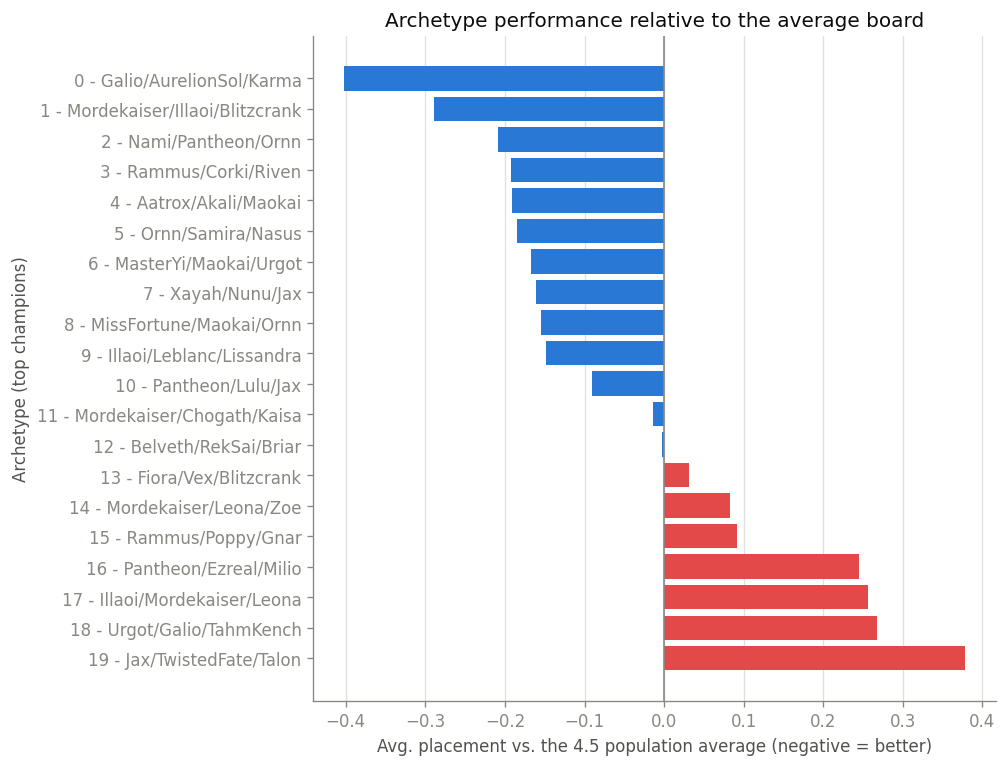

In [20]:
def short_board_label(cluster_id, n=3):
    board = archetype_table.set_index("cluster").loc[cluster_id, "board"]
    names = [c.split(" (")[0] for c in board.split(", ")][:n]
    return f"{cluster_id} - " + "/".join(names)


arch_delta = archetype_table.assign(delta=archetype_table["avg_placement"] - 4.5).sort_values("delta")
bar_labels = [short_board_label(cid) for cid in arch_delta["cluster"]]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
colors = [COLOR_BLUE if d < 0 else COLOR_RED for d in arch_delta["delta"]]
ax.barh(bar_labels, arch_delta["delta"], color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Avg. placement vs. the 4.5 population average (negative = better)")
ax.set_ylabel("Archetype (top champions)")
ax.set_title("Archetype performance relative to the average board")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

**Interpretation.** Unlike Section 4.2 (grouping by *match-level* `seed_tier`, which is
mathematically stuck at 4.5), grouping by *archetype* pulls unevenly from the 8 placement slots,
players choosing (or landing in) archetype X are not a random 1/8 slice of every lobby, so their
average placement can and does move away from 4.5. The spread here is real signal: some archetypes
average closer to top-4, others closer to bottom-4.

A caution worth stating plainly: **this ranks archetypes by correlation with better placement, not
by "power" in a causal sense.** An archetype's average placement reflects both how strong the comp
is *and* who tends to play it, how contested it tends to be (Section 6), and how far into the game
it typically develops (Section 5.4), all entangled together at this point. Distinctiveness (a very
recognizable, trait-heavy comp) and performance are also independent of each other here, a highly
distinctive archetype is not necessarily a good one, and a strong archetype isn't necessarily a
distinctive one.

### 5.4 Does rank tier shift which archetypes get played?

Section 4.2 showed `seed_tier` can't be used to compare placement directly. It *can* still be
compared on **pick rate**, does the population of archetypes people actually play shift with rank?
Reusing the same LOW (Iron/Bronze/Silver) vs. HIGH (Master and above) bucketing and minimum-sample
logic as `src/analysis/skill_gap.py`, now applied to whole archetypes instead of individual traits:

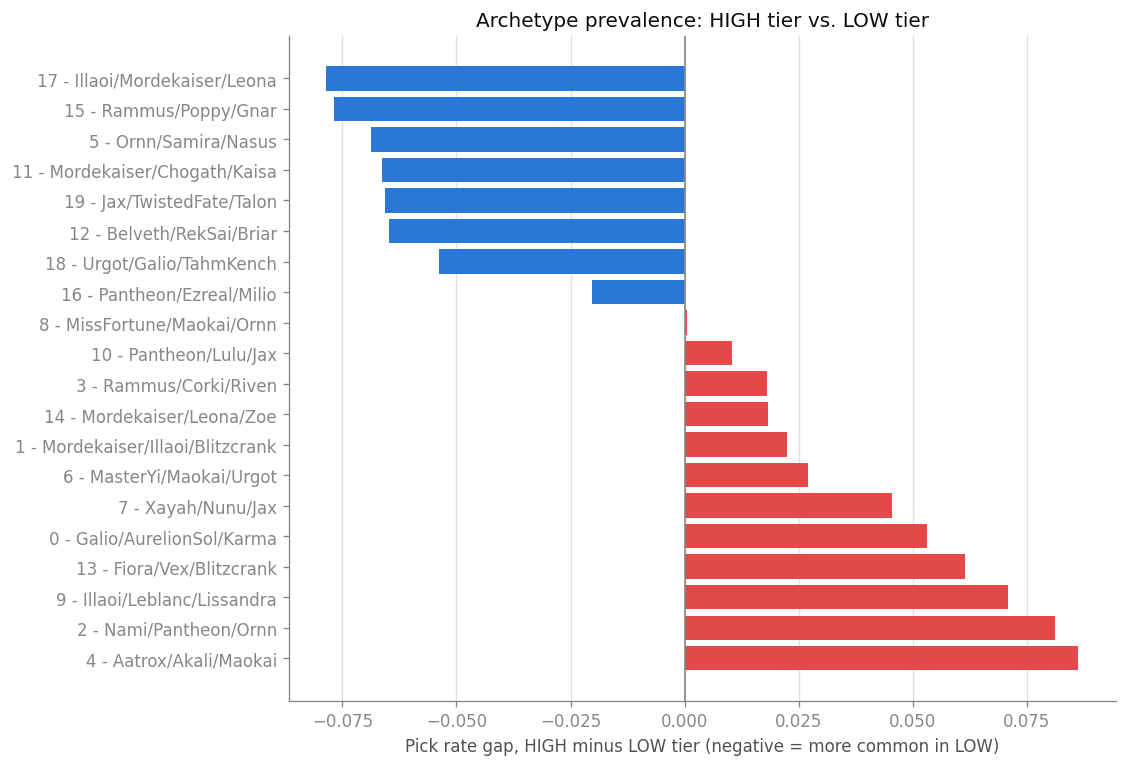

,pick_rate_LOW,pick_rate_HIGH,pick_rate_gap,top4_rate_LOW,top4_rate_HIGH
archetype_cluster,,,,,
4 - Aatrox/Akali/Maokai,0.054518,0.140825,0.086307,0.538203,0.551140
2 - Nami/Pantheon/Ornn,0.014556,0.095660,0.081103,0.566038,0.527461
9 - Illaoi/Leblanc/Lissandra,0.012931,0.083769,0.070838,0.692035,0.492198
13 - Fiora/Vex/Blitzcrank,0.012062,0.073591,0.061530,0.620493,0.477496
0 - Galio/AurelionSol/Karma,0.003731,0.056827,0.053097,0.588957,0.585976
7 - Xayah/Nunu/Jax,0.025199,0.070635,0.045435,0.623978,0.503414
6 - MasterYi/Maokai/Urgot,0.020965,0.047931,0.026967,0.667031,0.492984
1 - Mordekaiser/Illaoi/Blitzcrank,0.015747,0.038173,0.022426,0.645349,0.536237
14 - Mordekaiser/Leona/Zoe,0.031997,0.050381,0.018384,0.446352,0.531738


In [21]:
from analysis.tier_comparison import load_participants, summarize
from analysis.skill_gap import add_bucket, build_gap_table

participants_bucketed = add_bucket(load_participants(engine))
participants_per_bucket = participants_bucketed.groupby("seed_tier")["participant_id"].count()

archetype_picks = add_bucket(
    comp_df[["participant_id", "seed_tier", "placement", "archetype_cluster"]]
)
archetype_gap = build_gap_table(summarize(archetype_picks, participants_per_bucket, "archetype_cluster"))
archetype_gap = archetype_gap.rename(index=lambda cid: short_board_label(cid))

gap_sorted = archetype_gap.sort_values("pick_rate_gap")
fig, ax = plt.subplots(figsize=(9.5, 6.5))
colors = [COLOR_BLUE if g < 0 else COLOR_RED for g in gap_sorted["pick_rate_gap"]]
ax.barh(gap_sorted.index, gap_sorted["pick_rate_gap"], color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Pick rate gap, HIGH minus LOW tier (negative = more common in LOW)")
ax.set_title("Archetype prevalence: HIGH tier vs. LOW tier")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

archetype_gap[["pick_rate_LOW", "pick_rate_HIGH", "pick_rate_gap", "top4_rate_LOW", "top4_rate_HIGH"]] \
    .sort_values("pick_rate_gap", ascending=False)

The meta genuinely shifts with rank at the whole-archetype level, and by a lot for some archetypes,
several swing several-fold between the two brackets. The columns also expose something a pick-rate
comparison alone would miss: an archetype can be **more popular in the bracket where it performs
worse**, and rarer in the bracket where it performs better, a pattern invisible at the individual
trait level (Section 4.4), since it depends on the whole composition holding together rather than any
one piece in isolation.

### 5.5 A genuine timing signal, once placement is controlled for

`last_round` and `level` were flagged in Section 4.5 as too correlated with placement to use as
*predictive* features (Section 8 formalizes this as leakage). Used descriptively instead, to
characterize *how* an archetype tends to play out rather than to predict its outcome, they're
legitimate. The first pitfall to avoid: a **raw** archetype-level average of `last_round` is almost
perfectly correlated with `avg_placement` (bad boards simply die early, mechanically, in TFT), not a
timing signal, just a restatement of Section 5.3's ranking. Any real signal has to be measured
*within* a fixed placement value, comparing archetypes that reached the *same* outcome by different
paths.

In [22]:
from analysis.archetype_power_curve import load_power_curve_data, summarize_metric_by_placement

power_curve_df = comp_df[["participant_id", "match_id", "archetype_cluster", "placement"]].merge(
    pd.read_sql("SELECT id AS participant_id, last_round, level FROM participants", engine),
    on="participant_id", how="left",
)

naive_corr = (
    power_curve_df.groupby("archetype_cluster")
    .agg(avg_placement=("placement", "mean"), avg_last_round=("last_round", "mean"))
    .corr().iloc[0, 1]
)
print(f"Raw correlation, avg_placement vs. avg_last_round across archetypes: {naive_corr:.3f}")
print("-> too close to -1 to trust directly; controlling for placement below.")

round_delta = summarize_metric_by_placement(power_curve_df, "last_round").rename("last_round_delta")
level_delta = summarize_metric_by_placement(power_curve_df, "level").rename("level_delta")
power_curve = pd.concat([round_delta, level_delta], axis=1).sort_values("level_delta")
power_curve.index = [short_board_label(cid) for cid in power_curve.index]
power_curve

Raw correlation, avg_placement vs. avg_last_round across archetypes: -0.924
-> too close to -1 to trust directly; controlling for placement below.


,last_round_delta,level_delta
8 - MissFortune/Maokai/Ornn,0.262538,-0.771557
10 - Pantheon/Lulu/Jax,0.112738,-0.670927
14 - Mordekaiser/Leona/Zoe,0.075236,-0.508202
19 - Jax/TwistedFate/Talon,-0.072841,-0.476809
12 - Belveth/RekSai/Briar,0.105124,-0.355263
5 - Ornn/Samira/Nasus,0.051044,-0.352189
17 - Illaoi/Mordekaiser/Leona,-0.115433,-0.248717
16 - Pantheon/Ezreal/Milio,-0.082577,-0.192850
4 - Aatrox/Akali/Maokai,0.030655,-0.132470
18 - Urgot/Galio/TahmKench,-0.336800,-0.042968


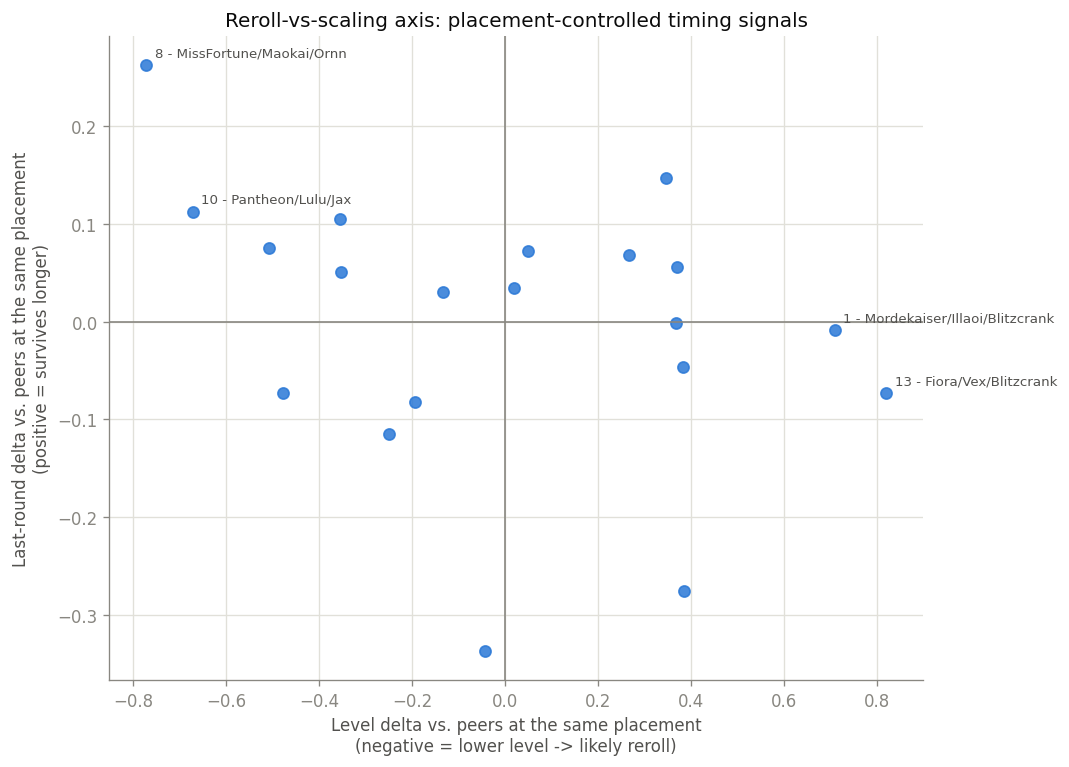

In [23]:
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(power_curve["level_delta"], power_curve["last_round_delta"], color=COLOR_BLUE, s=45, alpha=0.85)
ax.axhline(0, color=COLOR_MUTED, linewidth=1)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
for label, row in power_curve.loc[
    power_curve["level_delta"].abs().sort_values(ascending=False).head(4).index
].iterrows():
    ax.annotate(label, (row["level_delta"], row["last_round_delta"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8, color=COLOR_TEXT_SECONDARY)
ax.set_xlabel("Level delta vs. peers at the same placement\n(negative = lower level -> likely reroll)")
ax.set_ylabel("Last-round delta vs. peers at the same placement\n(positive = survives longer)")
ax.set_title("Reroll-vs-scaling axis: placement-controlled timing signals")
ax.grid(True, color=COLOR_GRID)
plt.tight_layout()
plt.show()

Once placement is controlled for, the two independent columns agree with each other, which is
what makes this reading trustworthy rather than coincidental: archetypes that reach a lower level
than their peers *for the same placement* also tend to survive somewhat longer than expected,
consistent with a low-XP, high-reroll strategy (spend gold rerolling for star levels instead of
leveling; a well-hit reroll board holds up once it comes online). Archetypes at the other end
(built around several 1-star flex picks rather than one committed carry) show the opposite
profile: gold went to XP rather than a single unit, because no one unit was being pushed to
2-3 stars.


## 6. Contest analysis

TFT is not a solo score to optimize, 8 players draw from the **same shared pool** of units and
items each round. If several players in the same lobby commit to the same archetype, they compete
for the same copies of the same key units, which should, in theory, weaken all of them relative to
playing an uncontested line. This section tests that directly.

### 6.1 Defining contest

For each participant, **contest level** = the number of *other* players (out of the remaining 7) in
the same match who were assigned to the same archetype cluster (Section 5). It's saved to
`data/processed/archetype_clusters.csv` by `src/analysis/archetypes.py` and consumed here through
`src/analysis/archetype_contest.py`, bucketed into **0 (uncontested) / 1 other / 2+ others**.

In [24]:
from analysis.archetypes import save_cluster_assignments
from analysis.archetype_contest import load_data, compute_contest_level, bucket_contest

clusters_path = save_cluster_assignments(comp_df, labels)
print(f"Saved archetype assignments to {clusters_path}")

contest_df = compute_contest_level(load_data())
contest_df["contest_bucket"] = contest_df["contest_level"].apply(bucket_contest)

contest_df["contest_level"].value_counts().sort_index()

Saved archetype assignments to data/processed/archetype_clusters.csv


contest_level
0    179655
1     78286
2     16836
3      2304
4       220
5        12
7        16
Name: count, dtype: int64

### 6.2 Global effect: does contest hurt placement?

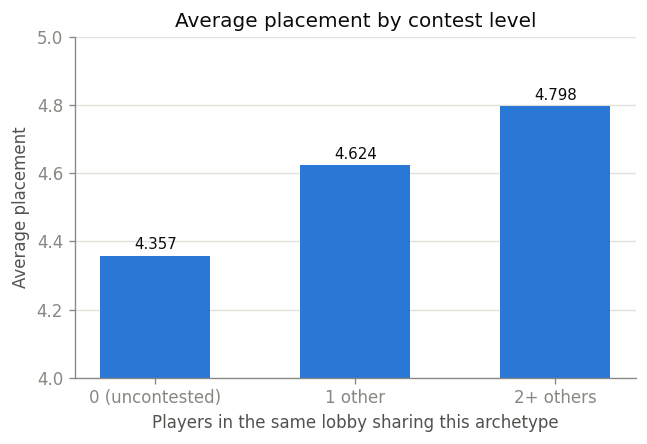

,mean,count
contest_bucket,,
0 (uncontested),4.357435,179655
1 other,4.624352,78286
2+ others,4.797658,19388


In [25]:
bucket_order = ["0 (uncontested)", "1 other", "2+ others"]
overall = contest_df.groupby("contest_bucket")["placement"].agg(["mean", "count"]).reindex(bucket_order)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(overall.index, overall["mean"], color=COLOR_BLUE, width=0.55)
for i, v in enumerate(overall["mean"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color=COLOR_TEXT)
ax.set_ylim(4.0, 5.0)
ax.set_ylabel("Average placement")
ax.set_xlabel("Players in the same lobby sharing this archetype")
ax.set_title("Average placement by contest level")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

overall

A clear, monotonic pattern: average placement worsens as more of the lobby shares the same
archetype. Unlike the `seed_tier` comparison in Section 4.2, this grouping is not stuck at 4.5 by
construction, contest level is a property of the specific 8-player lobby, not of the whole match, so
it can (and does) correlate with a real shift in outcome.

### 6.3 Per-archetype breakdown

Is this a uniform effect, or does contest sensitivity vary by archetype?

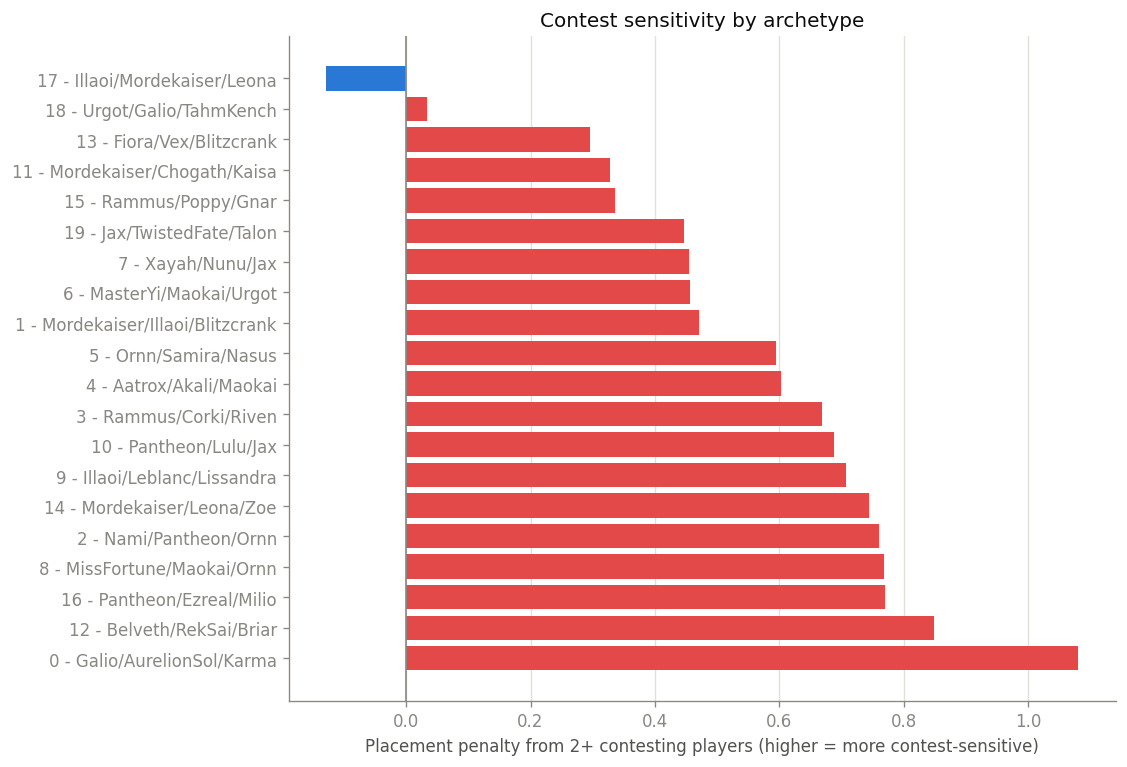

contest_bucket,0 (uncontested),1 other,2+ others,delta_2plus_vs_uncontested
0 - Galio/AurelionSol/Karma,3.960192,4.480208,5.041026,1.080833
12 - Belveth/RekSai/Briar,4.299723,4.792332,5.148974,0.849251
16 - Pantheon/Ezreal/Milio,4.681254,4.955832,5.451613,0.770359
8 - MissFortune/Maokai/Ornn,4.232355,4.685780,5.000000,0.767645
2 - Nami/Pantheon/Ornn,4.158990,4.489557,4.918587,0.759597
14 - Mordekaiser/Leona/Zoe,4.430507,4.979224,5.174648,0.744141
9 - Illaoi/Leblanc/Lissandra,4.193733,4.601413,4.900459,0.706727
10 - Pantheon/Lulu/Jax,4.283143,4.913957,4.970588,0.687445
3 - Rammus/Corki/Riven,4.215233,4.450915,4.884283,0.669050
4 - Aatrox/Akali/Maokai,4.092566,4.439030,4.695944,0.603378


In [26]:
per_arch = contest_df.groupby(["archetype_cluster", "contest_bucket"]).agg(
    n=("participant_id", "count"), avg_placement=("placement", "mean"),
).reset_index()
pivot = per_arch.pivot(index="archetype_cluster", columns="contest_bucket", values="avg_placement")
pivot = pivot[bucket_order]
pivot["delta_2plus_vs_uncontested"] = pivot["2+ others"] - pivot["0 (uncontested)"]
pivot.index = [short_board_label(cid) for cid in pivot.index]

pivot_sorted = pivot.sort_values("delta_2plus_vs_uncontested")
fig, ax = plt.subplots(figsize=(9.5, 6.5))
colors = [COLOR_RED if d > 0 else COLOR_BLUE for d in pivot_sorted["delta_2plus_vs_uncontested"]]
ax.barh(pivot_sorted.index, pivot_sorted["delta_2plus_vs_uncontested"], color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Placement penalty from 2+ contesting players (higher = more contest-sensitive)")
ax.set_title("Contest sensitivity by archetype")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

pivot.sort_values("delta_2plus_vs_uncontested", ascending=False)

Most archetypes lose noticeably when contested by 2+ others; a few sit close to flat instead. A
plausible reading for the flattest ones: they're already among the weaker archetypes (Section 5.3),
so they're rarely contested in the first place (few players choose them even when uncontested) —
that limits how much *more* they can be hurt by contest. Their weakness looks structural, not
resource-competition-driven.

### 6.4 Limits of this analysis, correlation, not a randomized experiment

This is an **observational** comparison, not a controlled experiment, and it should not be read as
"contest *causes* a fixed placement penalty." A few concrete confounds:

- **Selection effect.** Which archetype a player ends up in, and how contested it turns out to be,
  is not randomly assigned, it depends on choices made throughout the game (including reacting to
  what the player *sees* others taking), and on server-side matchmaking/shop randomness that isn't
  observed here. Skilled players may be more likely to pivot away from a visibly-contested line,
  which would make contest look *less* damaging than it truly is for players who don't pivot.
- **Reverse causality risk.** A weak start (bad early shop, bad positioning) can itself push a player
  toward whatever archetype is left uncontested, rather than contest being the cause of a later bad
  placement, the correlation could partly run the other way.
- **No randomization.** A genuinely causal claim would need something like an experiment or a
  natural instrument that varies contest level independently of player skill and archetype quality,
  neither exists in this dataset. What can be said is a robust **association**: higher contest levels
  are associated with worse outcomes, consistently across most archetypes, which is already a useful
  and non-obvious finding, just not proof of a fixed causal effect size.

## 7. Feature engineering

The archetype clustering (Section 5) used a deliberately narrow, binarized view of composition. The
placement model (Section 9 onward) instead needs the **full feature matrix** built by
`src/features/build_feature_matrix.py`, which flattens the normalized database into one row per
participant:

| Feature group | Encoding | Rationale |
|---|---|---|
| `trait__<name>` | active tier (`tier_current`, 0 if inactive) | Tier matters, not just presence, a 2-piece Vanguard bonus is a different signal from a 6-piece one |
| `champ__<character_id>` | max star level fielded (0 if not played) | Captures both *which* champions and *how invested* the player was in them |
| `item__<item_name>` | count across the whole board | An item built twice (e.g. two Infinity Edges) is a stronger signal than one |
| `seed_tier`, `patch` | categorical | Context that composition-only features can't capture |
| `gold_left` | numeric | Economy-management signal, not an outcome-of-the-game column |
| `level`, `last_round`, `time_eliminated`, `players_eliminated`, `total_damage_to_players` | numeric | Present in the matrix, but **excluded from the model**, Section 8 |

Non-player companion/encounter units (Section 3.3) are excluded before this table is built, so they
never reach a `champ__` column.

In [27]:
FEATURE_MATRIX_PATH = "data/processed/feature_matrix.csv"
matrix = pd.read_csv(FEATURE_MATRIX_PATH, dtype={"patch": str})

trait_cols = [c for c in matrix.columns if c.startswith("trait__")]
item_cols = [c for c in matrix.columns if c.startswith("item__")]
champ_cols = [c for c in matrix.columns if c.startswith("champ__")]

print(f"{matrix.shape[0]:,} rows x {matrix.shape[1]} columns")
print(f"  {len(trait_cols)} trait columns, {len(item_cols)} item columns, {len(champ_cols)} champion columns")
print(f"  + context columns: {[c for c in matrix.columns if not c.startswith(('trait__', 'item__', 'champ__'))]}")
matrix.iloc[:3, :12]

277,329 rows x 299 columns
  41 trait columns, 185 item columns, 62 champion columns
  + context columns: ['participant_id', 'match_id', 'placement', 'level', 'gold_left', 'last_round', 'players_eliminated', 'time_eliminated', 'total_damage_to_players', 'seed_tier', 'patch']


,participant_id,match_id,placement,level,gold_left,last_round,players_eliminated,time_eliminated,total_damage_to_players,seed_tier,patch,trait__TFT17_ADMIN
0,1,EUW1_7932594738,6,6,4,30,0,1690.058105,63,MASTER_PLUS,16.14,0.0
1,2,EUW1_7932594738,2,7,7,37,1,2062.541992,168,MASTER_PLUS,16.14,0.0
2,3,EUW1_7932594738,5,9,4,31,1,1735.291870,82,MASTER_PLUS,16.14,0.0


**Why one-hot/count encoding instead of, say, embeddings or a smaller hand-picked feature set:**
with only ~40 traits, ~65 champions and ~185 items, a wide sparse matrix (~290 columns for ~283k
rows) is small enough for a tree-based model to handle directly and interpret feature-by-feature
via SHAP (Section 12). A hand-picked subset would risk discarding exactly the specific champion/item
signal that turns out to matter most later. The tradeoff is sparsity: most `item__`/`champ__`
columns are zero for most rows, since no single board fields more than ~9 champions or ~30 total
item components out of the full pool.

**Why the archetype cluster label itself isn't included as a model feature:** it's *derived from*
the same trait/champion columns already in the matrix (Section 5.1), so adding it would be
redundant rather than new signal. A tree-based model can already recover any interaction the
cluster label would encode by splitting on the underlying trait/champion columns directly, and
Section 12's SHAP breakdown gives strictly more granular attribution (per champion/item) than a
single cluster ID would. `src/modeling/train_model.py` keeps it and drops the rest (`DROP_COLS`),
including `level` despite its more ambiguous case above — the safer call given the entanglement
described in 8.1.


## 8. Data leakage

Section 4.5's correlation matrix already flagged the problem: several numeric columns correlate with
`placement` at 0.5-0.9, far beyond what any legitimate composition signal should reach. This section
makes the mechanism explicit and demonstrates, concretely, what happens if they're left in.

### 8.1 Why these columns are dangerous

In TFT, **placement is determined by elimination order**, the last player standing is 1st, the
first eliminated is 8th (or lower placements are assigned by remaining HP if the game ends before
full elimination). That means:

- **`last_round`** and **`time_eliminated`** record *when* a player was knocked out, for anyone who
  isn't top-1, this is a near-direct encoding of their placement, not a cause of it.
- **`players_eliminated`** and **`total_damage_to_players`** accumulate mechanically over a longer
  game, surviving longer (i.e., placing better) gives more opportunities to eliminate others and
  deal damage, so these are *downstream consequences* of doing well, not composition signal that
  *causes* doing well.
- **`level`** is more ambiguous, it reflects a real strategic choice (reroll low vs. level high,
  Section 5.5), but it's also mechanically higher for a player who survives longer and keeps
  collecting XP, which partially entangles it with the outcome too.

Using any of these as **predictive features** would let the model "predict" placement by looking at
information that only exists *because* the game already ended a certain way, a model trained this
way isn't learning what makes a good composition, it's learning to read the scoreboard.

### 8.2 Confirming and visualizing the leak

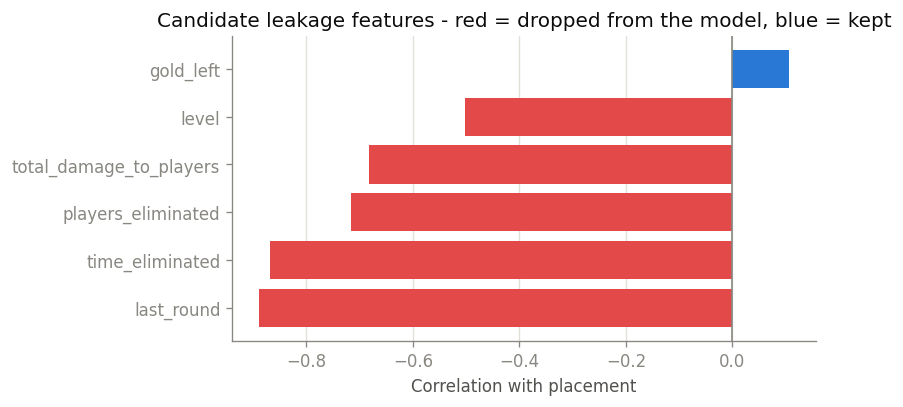

last_round                -0.889872
time_eliminated           -0.867683
players_eliminated        -0.715812
total_damage_to_players   -0.683031
level                     -0.502728
gold_left                  0.107223
Name: placement, dtype: float64

In [28]:
from modeling.train_model import DROP_COLS

leak_check = matrix[[
    "placement", "level", "gold_left", "last_round",
    "players_eliminated", "time_eliminated", "total_damage_to_players",
]].corr()["placement"].drop("placement").sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = [COLOR_RED if col in DROP_COLS else COLOR_BLUE for col in leak_check.index]
ax.barh(leak_check.index, leak_check.values, color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.set_xlabel("Correlation with placement")
ax.set_title("Candidate leakage features - red = dropped from the model, blue = kept")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

leak_check

`last_round` and `time_eliminated` sit at roughly -0.9 and -0.87, essentially restatements of the
target, not predictive signal to be *learned*. `gold_left`, by contrast, correlates only around 0.11:
weak enough to be a genuine (if minor) economy-management signal rather than an outcome proxy, so
`src/modeling/train_model.py` keeps it and drops the rest (`DROP_COLS`, including `level` despite its
more ambiguous case above, the safer call given the entanglement described in 8.1).

### 8.3 What "looking too good" actually looks like

To make the abstract warning concrete: below, the exact same model architecture and time-based split
used for the real model (Section 9) is trained **twice**, once correctly (leakage columns excluded,
matching `src/modeling/train_model.py`), and once, *for illustration only*, with the leakage columns
left in. This second model is not part of the project's pipeline and is not used anywhere past this
cell, it exists purely to show the effect.


In [29]:
from modeling.train_model import load_and_prepare, train, report, prepare_categoricals, TEST_PATCHES

X_train, y_train, X_test, y_test, train_df, test_df = load_and_prepare()

print("=== Correct model (leakage columns excluded) ===")
model_clean = train(X_train, y_train)
report(y_train, model_clean.predict(X_train), "Train")
report(y_test, model_clean.predict(X_test), "Test (held-out future patches)")

=== Correct model (leakage columns excluded) ===



--- Train (n=175127) ---
  MAE: 1.157  (baseline, always predict mean placement: 1.999)
  Top4 accuracy: 0.820



--- Test (held-out future patches) (n=102202) ---
  MAE: 1.181  (baseline, always predict mean placement: 2.000)
  Top4 accuracy: 0.814


In [30]:
# Illustration only - NOT part of src/modeling/train_model.py's methodology.
leak_cols_to_keep = ["level", "last_round", "players_eliminated", "time_eliminated", "total_damage_to_players"]
only_drop = ["participant_id", "match_id", "placement"]

df_leak = pd.read_csv(FEATURE_MATRIX_PATH, dtype={"patch": str})
is_test_leak = df_leak["patch"].isin(TEST_PATCHES)
train_leak, test_leak = df_leak[~is_test_leak].copy(), df_leak[is_test_leak].copy()

feature_cols_leak = [c for c in df_leak.columns if c not in only_drop]
X_train_leak, y_train_leak = train_leak[feature_cols_leak], train_leak["placement"]
X_test_leak, y_test_leak = test_leak[feature_cols_leak], test_leak["placement"]
X_train_leak, X_test_leak = prepare_categoricals(X_train_leak, X_test_leak)

print("=== Illustration only: same model, leakage columns LEFT IN ===")
model_leak = train(X_train_leak, y_train_leak)
report(y_train_leak, model_leak.predict(X_train_leak), "Train (leaky)")
report(y_test_leak, model_leak.predict(X_test_leak), "Test (leaky)")

=== Illustration only: same model, leakage columns LEFT IN ===



--- Train (leaky) (n=175127) ---
  MAE: 0.538  (baseline, always predict mean placement: 1.999)
  Top4 accuracy: 0.919



--- Test (leaky) (n=102202) ---
  MAE: 0.543  (baseline, always predict mean placement: 2.000)
  Top4 accuracy: 0.919


The leaky version's MAE drops sharply on paper: it would look like a clear improvement to anyone
just comparing headline metrics. **It is not a better model.** It has simply learned to read
`last_round`/`time_eliminated` back into a placement number, which is nearly circular (Section 8.1)
rather than genuinely predictive of anything a player could act on before the game ends. This is
exactly the trap the section's title warns about: a leaked model can look excellent by every metric
you check, while being methodologically useless for the actual question ("what about the *board*
predicts placement"). The only way to catch it is to reason about *when in the game* each feature
becomes known, not just how strong its correlation looks.

## 9. Machine learning model

### 9.1 Framing: regression, not classification


Before the modeling choices below: the input to this model is each player's board as it stood at
game end (final composition, items, traits), so "predicting placement" here means recovering the
outcome from a complete, retrospective snapshot, not forecasting it from a partial or pre-game
state. This is why raw performance numbers in Sections 10-13 shouldn't be read as "how good is
this at forecasting a match", but as "how much of the final placement is explained by what the
board looked like at the end."

`placement` is **ordinal** (1 is strictly better than 2, which is strictly better than 3, ...), not
a set of unordered categories. Treating it as a plain multiclass classification problem would throw
away that structure, a model predicting "2" for a true "1" and a model predicting "8" for a true "1"
would be penalized identically under 0/1 accuracy, even though the first is a near-miss and the
second is a completely wrong read of the board. **Regression** (predicting a continuous value, then
optionally rounding/clipping to 1-8) naturally respects the ordering: a prediction of 1.8 for a true
placement of 1 is treated as a small error, not a total miss, which matches the actual cost structure
of being wrong here.

### 9.2 Model and hyperparameters

`src/modeling/train_model.py` uses scikit-learn's **`HistGradientBoostingRegressor`**, a histogram-
based gradient boosting model (in the same family as LightGBM/XGBoost). Reasons this fits the problem
well:

- **Handles ~290 sparse, mixed-scale features natively**, without needing to standardize/scale
  anything, important here since `item__`/`champ__` columns are mostly zero and on very different
  scales (star level 0-3 vs. item count 0-3 vs. trait tier 0-6).
- **Native categorical support** (`categorical_features=["seed_tier", "patch"]`), the model handles
  `seed_tier`/`patch` as unordered categories directly via its own optimal-partition search, so no
  one-hot expansion is needed for them, and (as noted in Section 3.6) it doesn't depend on the codes
  being in any particular order.
- **Interpretable via SHAP** (Section 12), being tree-based, exact SHAP values can be computed
  efficiently with `TreeExplainer`, rather than needing a slower model-agnostic approximation.
- Hyperparameters are left at scikit-learn's defaults (`max_iter=100`, `learning_rate=0.1`,
  `max_leaf_nodes=31`) aside from `random_state=42` for reproducibility, no hyperparameter search was
  run. This is a reasonable starting point for a first honest baseline, not a claim that these are
  optimal; a natural next step (not done here) would be a proper search validated on a
  patch-held-out split, consistent with Section 11's methodology, rather than a random-CV search that
  would reintroduce the concept-drift blind spot this project is specifically trying to avoid.

### 9.3 Preprocessing

- **Categorical encoding:** `seed_tier`/`patch` are mapped to integer codes fit on the *training*
  set only (`prepare_categoricals` in `src/modeling/train_model.py`), categories seen only in the
  test set (a genuinely new patch, for instance) become `NaN`, which `HistGradientBoostingRegressor`
  handles natively as "missing" rather than crashing or silently mis-encoding.
- **Everything else is used as-is**, trait tiers, champion star levels and item counts are already
  small integers on a natural scale, and tree-based models split on raw values without needing
  normalization.

### 9.4 Train/test split

**Time-based**, not random: train on patches **16.8-16.14**, test on **16.15-16.16**, which the model
never sees during training. Section 11 explains why this matters and quantifies the alternative.

### 9.5 Training the model

This is the model used for every result from here through Section 13, it's the same "correct,
leakage-free" model already fit once in Section 8.3 (`model_clean`) for comparison purposes; it is
not retrained here. The patch-label fix from Section 3.6 is applied now, once, so every chronological
grouping/plot from this point on uses the correct patch strings.

In [31]:
model = model_clean  # trained in Section 8.3, on the leakage-free feature set

# Section 3.6 fix: load_and_prepare() reads feature_matrix.csv without a dtype hint,
# so train_df/test_df["patch"] currently carries the float-corrupted labels. Re-attach
# the correctly-typed patch string (does not touch X_train/X_test, so the already-fitted
# model and its predictions are unaffected - this only fixes reporting/grouping below).
patch_lookup = pd.read_csv(FEATURE_MATRIX_PATH, usecols=["participant_id", "patch"],
                            dtype={"patch": str}).set_index("participant_id")["patch"]
train_df = train_df.assign(patch=patch_lookup.reindex(train_df["participant_id"]).values)
test_df = test_df.assign(patch=patch_lookup.reindex(test_df["participant_id"]).values)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

print(f"Train: {len(X_train):,} rows | patches: {sorted(train_df['patch'].unique(), key=patch_sort_key)}")
print(f"Test:  {len(X_test):,} rows | patches: {sorted(test_df['patch'].unique(), key=patch_sort_key)}")

Train: 175,127 rows | patches: ['16.8', '16.9', '16.10', '16.11', '16.12', '16.13', '16.14']
Test:  102,202 rows | patches: ['16.15', '16.16']


## 10. Evaluation

### 10.1 Metrics

- **MAE (Mean Absolute Error)**: average absolute difference between predicted and true placement,
  in placement units (1-8 scale), directly interpretable ("the model is off by X places on
  average").
- **Baseline**: MAE of always predicting the training-set mean placement (~4.5) for everyone, the
  minimum bar any model needs to clear to be worth using at all.
- **Top-4 accuracy**: whether the model's rounded prediction agrees with the true outcome on the
  binary "did this player cash out top-4 or not" question, the single most consequential threshold
  in ranked TFT, since top-4 vs. bottom-4 is what determines LP gain/loss.

In [32]:
report(y_train, pred_train, "Train")
report(y_test, pred_test, "Test (held-out future patches 16.15/16.16)")


--- Train (n=175127) ---
  MAE: 1.157  (baseline, always predict mean placement: 1.999)
  Top4 accuracy: 0.820

--- Test (held-out future patches 16.15/16.16) (n=102202) ---
  MAE: 1.181  (baseline, always predict mean placement: 2.000)
  Top4 accuracy: 0.814


### 10.2 What this means, concretely, in TFT terms

An MAE around 1.1-1.2 on the held-out future patches, against a baseline of ~2.0, means the model is
**typically off by a little over one placement position**, e.g. predicting a true 3rd-place finish
as roughly 2nd-4th, using nothing but the final board (plus tier/patch/gold). That is a substantial,
non-trivial improvement over "always guess the middle," but it is nowhere near perfect, which is
exactly what the framing in Section 1 predicted: a static final-board snapshot cannot see matchups,
positioning, timing execution, or (Section 3.4) augments. That's an unavoidable ceiling on how good
*any* model built from this feature set could be — not a flaw specific to this particular model.

Top-4 accuracy is the more actionable number for a player asking "is my board good": roughly 8 in 10
predictions correctly call whether a board cashes out top-4, against a baseline of 50% (each match
has exactly 4 top-4 and 4 bottom-4 finishers, so a coin flip is the correct no-skill reference here,
not a naive "always predict top-4" rule).

## 11. Concept drift & temporal validation

### 11.1 Why a random split would be misleading here

Riot rebalances TFT with every patch, champion/item/trait power levels shift, sometimes
drastically. A model's relationship between "board composition" and "placement" is therefore not
fixed over time: **what wins changes as the game changes**, a textbook case of *concept drift*.

A standard random 80/20 train/test split would scatter matches from the *same* patches (often even
matches close together in time, reflecting the same balance patch and the same live meta) across both
train and test. A model can then partly succeed on the test set simply by having memorized
patch-specific patterns it also saw plenty of in training, this would look like good generalization
while actually hiding the exact risk this project cares about: **how the model performs on a patch it
has genuinely never seen.** The project's split instead trains on patches 16.8-16.14 and holds out
16.15/16.16 entirely, which is the only way to honestly measure that.

### 11.2 Quantifying the difference: random split vs. time-based split

To make this concrete rather than asserted, the same model/features are compared under both
strategies. The random-split model below is for this comparison only, it is not used anywhere else
in this notebook.

In [33]:
from sklearn.model_selection import train_test_split
from modeling.train_model import DROP_COLS

df_all = pd.read_csv(FEATURE_MATRIX_PATH, dtype={"patch": str})
feature_cols = [c for c in df_all.columns if c not in DROP_COLS]
X_all, y_all = df_all[feature_cols], df_all["placement"]

test_fraction = len(X_test) / len(df_all)
X_train_rnd, X_test_rnd, y_train_rnd, y_test_rnd = train_test_split(
    X_all, y_all, test_size=test_fraction, random_state=RANDOM_STATE
)
X_train_rnd, X_test_rnd = prepare_categoricals(X_train_rnd, X_test_rnd)

print(f"=== Comparison-only model: RANDOM {1 - test_fraction:.0%}/{test_fraction:.0%} split "
      f"(same test size as the real time-based split) ===")
model_random = train(X_train_rnd, y_train_rnd)
report(y_train_rnd, model_random.predict(X_train_rnd), "Train (random split)")
report(y_test_rnd, model_random.predict(X_test_rnd), "Test (random split)")

=== Comparison-only model: RANDOM 63%/37% split (same test size as the real time-based split) ===



--- Train (random split) (n=175127) ---
  MAE: 1.155  (baseline, always predict mean placement: 1.998)
  Top4 accuracy: 0.820



--- Test (random split) (n=102202) ---
  MAE: 1.173  (baseline, always predict mean placement: 2.002)
  Top4 accuracy: 0.816


### 11.3 Degradation by patch, under the real (time-based) evaluation

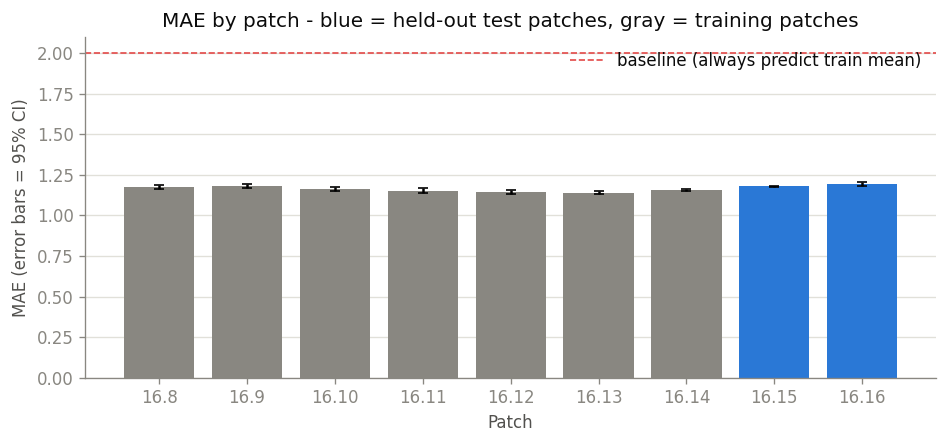

,patch,mae,ci95,n
7,16.8,1.176591,0.011197,22496
8,16.9,1.179248,0.013234,16122
0,16.10,1.159923,0.012294,18769
1,16.11,1.152998,0.013482,15568
2,16.12,1.145648,0.013604,15494
3,16.13,1.139031,0.009575,30621
4,16.14,1.156911,0.007132,56057
5,16.15,1.178139,0.005869,85800
6,16.16,1.193879,0.013569,16402


In [34]:
from sklearn.metrics import mean_absolute_error
from modeling.train_model import TEST_PATCHES

all_pred_df = pd.concat([
    train_df.assign(pred=pred_train),
    test_df.assign(pred=pred_test),
])
all_pred_df["abs_error"] = np.abs(all_pred_df["placement"] - all_pred_df["pred"])

patch_mae = (
    all_pred_df.groupby("patch")["abs_error"]
    .agg(mae="mean", std="std", n="count")
    .reset_index()
)
# 95% CI via normal approximation (n is in the thousands for every patch, so the
# CLT holds comfortably here even though abs_error itself is right-skewed).
patch_mae["ci95"] = 1.96 * patch_mae["std"] / np.sqrt(patch_mae["n"])
patch_mae = patch_mae.sort_values("patch", key=lambda s: s.map(patch_sort_key))
is_test_patch = patch_mae["patch"].isin(TEST_PATCHES)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(patch_mae["patch"], patch_mae["mae"], yerr=patch_mae["ci95"], capsize=3,
       color=[COLOR_BLUE if t else COLOR_MUTED for t in is_test_patch])
baseline_mae = mean_absolute_error(y_test, np.full_like(pred_test, y_train.mean()))
ax.axhline(baseline_mae, color=COLOR_RED, linestyle="--", linewidth=1, label="baseline (always predict train mean)")
ax.set_ylabel("MAE (error bars = 95% CI)")
ax.set_xlabel("Patch")
ax.set_title("MAE by patch - blue = held-out test patches, gray = training patches")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

patch_mae[["patch", "mae", "ci95", "n"]]


### 11.4 What this reveals about generalization

Comparing 11.2 and 11.3 directly: the random-split test MAE and the time-based test MAE on 16.15/16.16
come out **close to each other** (random split slightly lower). If concept drift were severe, the
random split would have looked substantially, not marginally, more optimistic, the model transfers
to genuinely unseen future patches almost as well as it fits data drawn from the same era as training.
That is a real, useful result, but it should not be over-read as "no concept drift": it means drift is
*mild over this particular 2-patch horizon*, for *this* feature set, not that the model would stay
this accurate indefinitely as patches keep accumulating further from the training window.

**Are the per-patch differences in 11.3 real, or noise?** With 95% CIs added (normal approximation,
every patch has thousands to tens of thousands of test rows, so the CLT holds comfortably here even
though `abs_error` itself is right-skewed), most **adjacent** patches turn out to overlap and aren't
reliably distinguishable from each other on their own, e.g. 16.8 vs. 16.9, or 16.11 vs. 16.12. What
*is* clearly separated is the 16.13 → 16.14 → 16.15 stretch (each CI sits entirely above the previous
one) and the two extremes: 16.13 (the best-fit patch, MAE 1.139) vs. 16.16 (the worst, MAE 1.194) don't
overlap at all. So the **shape** is real, the model genuinely fits some patches better than others,
but most of the individual bar-to-bar wiggle within that shape is within noise, and the total spread
across all 9 patches is modest in absolute terms (~0.055 MAE, best to worst). Large `n` means even a
small, real effect clears a significance bar easily; the CI answers "is this shape real," not "does it
matter a lot", here the honest answer is yes to the first, only modestly to the second.

With that read, the shape itself still holds: MAE traces a shallow **U-shape** across the training
patches, highest at the earliest patches (16.8/16.9, the least-represented and most-dated), lowest
around the middle of the training window (16.12/16.13), then rising again through 16.14 into the two
held-out patches, with 16.16 (the furthest from training) the single worst patch overall. That shape is
consistent with an ordinary distance-from-training-distribution effect rather than a sudden
meta-breaking shift: the model does best on patches most similar to the bulk of what it trained on, and
gets gradually less accurate the further a patch sits from that center, in either direction in time.

The practical takeaway for any live use of this model: it should be treated as valid for a limited
window after its last training patch, with **periodic retraining on a recent window of patches** built
into any deployment plan, not as a one-off model that stays accurate indefinitely as the game keeps
changing under it. This dataset simply doesn't contain a patch far enough removed to show what happens
after a genuinely drastic rebalance; the mild degradation measured here is a lower bound on real-world
drift risk, not an upper one.


## 12. Explainability with SHAP

MAE and top-4 accuracy say *how well* the model predicts. They say nothing about *which* features
drive those predictions, or in which direction. **SHAP** (SHapley Additive exPlanations) decomposes
each individual prediction into per-feature contributions, additive and consistent, which is what
makes it usable both for a single board and for aggregate importance across many boards.

`src/modeling/explain_model.py` computes exact SHAP values via `shap.TreeExplainer` (tractable here
specifically because `HistGradientBoostingRegressor` is a tree ensemble) on a sample of the held-out
test set.

In [35]:
from modeling.explain_model import compute_shap_values, shap_summary_table, category_breakdown, SAMPLE_SIZE

sample, shap_values = compute_shap_values(model, X_test, sample_size=SAMPLE_SIZE, random_state=RANDOM_STATE)
shap_summary = shap_summary_table(sample, shap_values)

print(f"SHAP values computed on {len(sample):,} held-out test rows.")
print("Negative mean_signed_shap = pushes toward a BETTER placement (1 is best).\n")
shap_summary.head(20)

SHAP values computed on 2,000 held-out test rows.
Negative mean_signed_shap = pushes toward a BETTER placement (1 is best).



,mean_abs_shap,mean_signed_shap
champ__TFT17_Blitzcrank,0.252607,-0.028805
gold_left,0.182258,-0.006330
champ__TFT17_Shen,0.156720,-0.033824
champ__TFT17_Jhin,0.154489,0.001206
champ__TFT17_Kindred,0.151851,-0.016636
item__TFT_Item_GargoyleStoneplate,0.137619,-0.044755
item__TFT_Item_WarmogsArmor,0.135967,-0.013134
item__TFT_Item_MadredsBloodrazor,0.118938,0.008096
item__TFT_Item_Redemption,0.114058,-0.002783
champ__TFT17_Karma,0.099034,-0.012652


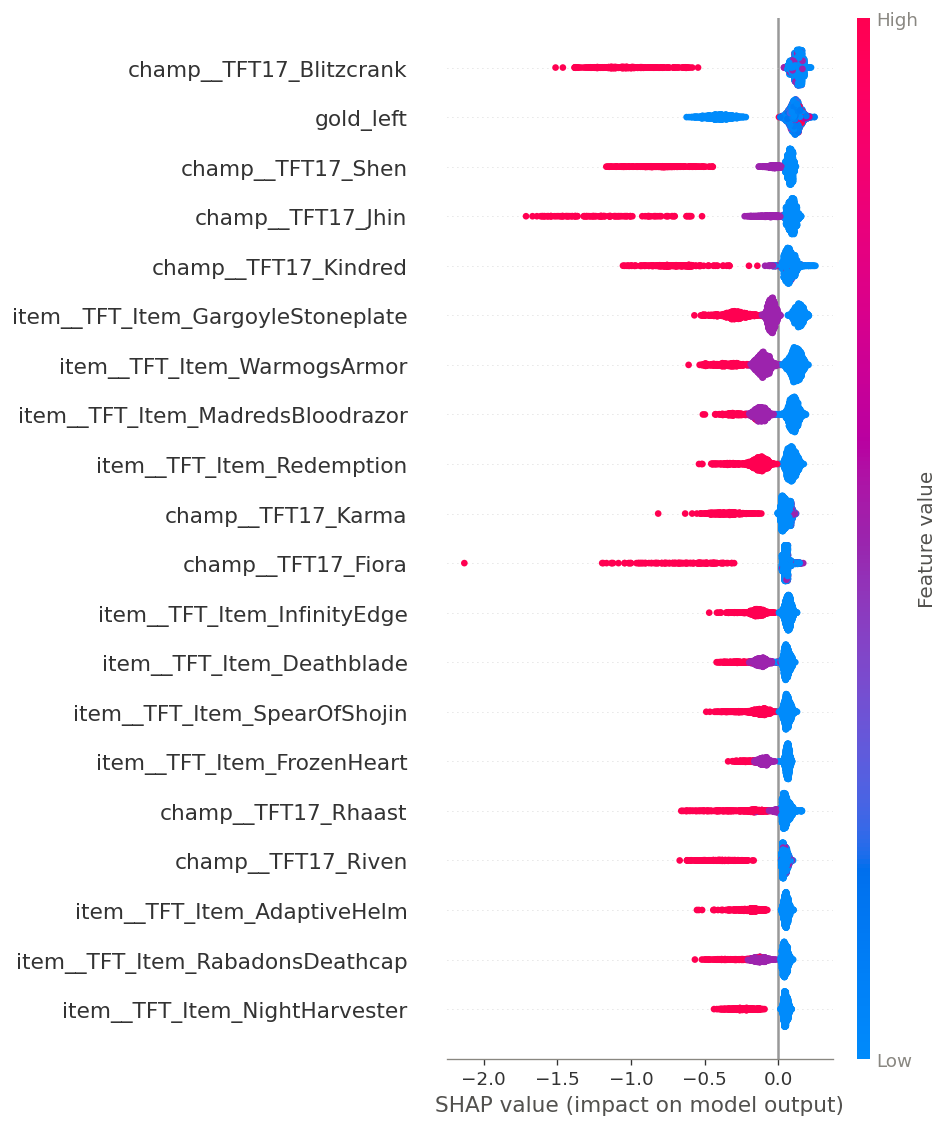

In [36]:
import shap
shap.summary_plot(shap_values, sample, max_display=20, show=False)
plt.tight_layout()
plt.show()

### 12.1 Reading the ranking

The top of the ranking is dominated by **specific high-star champions and specific key items**, well
ahead of individual traits taken in isolation. This lines up with, and gives a mechanistic
explanation for, Section 5's finding that whole-archetype identity (which pieces, together) matters
more than any single trait's pick rate alone: the model has effectively rediscovered that a comp's
strength lives in its star-leveled carries and their itemization, not in trait counts by themselves.

`gold_left` also ranks highly by magnitude (mean |SHAP| = 0.182, 2nd overall), but its **mean signed**
SHAP (-0.006) is close to zero, not the clearly positive value the raw 0.11 correlation (Section 8.2)
might suggest on its own. Read together, this means `gold_left` matters a lot on a per-board basis, but
not through one single "more gold = worse" direction: the model has learned a *non-monotonic*
relationship, e.g. a small cushion of gold reads differently than a large hoarded pile, that a plain
correlation collapses into one number and a plain mean SHAP nearly cancels out. Section 9's econ-signal
framing still applies to the *variable*, just not as a one-directional story: a board that ends with an
unusually large pile of unspent gold is a plausible sign of a board too weak to find anything worth
buying, but that story doesn't extend cleanly across the whole range of `gold_left`.

### 12.2 Does rank tier still matter, once composition is fixed?

Section 4.2 established that `seed_tier` cannot show a clean placement effect through simple grouping
for the bot-free tiers (mechanically fixed at 4.5), and that the low tiers' apparent deviation from 4.5
is itself a bot-driven artifact (Section 4.2) rather than a skill signal. SHAP asks a genuinely
different question: for two *fixed, identical* boards, does the model's prediction still shift
depending on the tier tag attached to them?


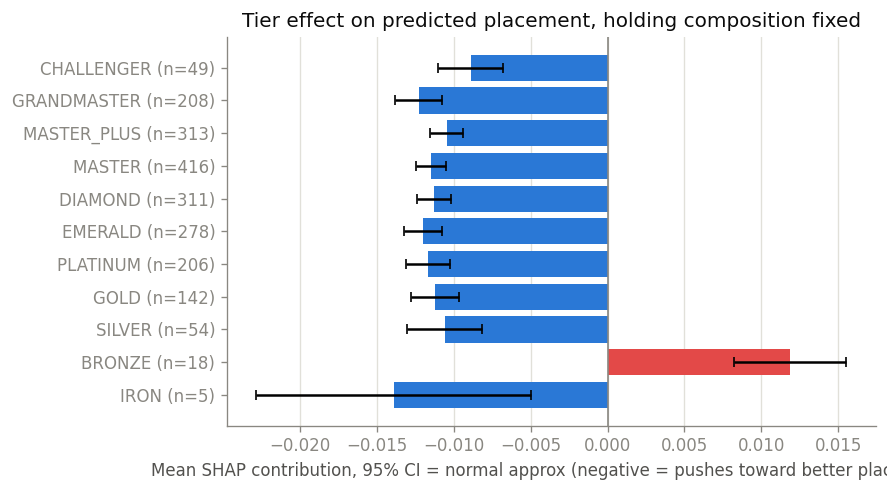

Bootstrap 95% CI (2,000 resamples) as a cross-check against the normal-approximation CI above:


,mean,ci95,boot_lo,boot_hi,boot_includes_zero,n
seed_tier,,,,,,
IRON,-0.0139,0.0089,-0.0231,-0.0072,False,5
BRONZE,0.0119,0.0036,0.0086,0.0157,False,18
SILVER,-0.0106,0.0024,-0.0132,-0.0084,False,54
GOLD,-0.0113,0.0016,-0.0128,-0.0098,False,142
PLATINUM,-0.0117,0.0014,-0.0131,-0.0102,False,206
EMERALD,-0.0120,0.0012,-0.0132,-0.0108,False,278
DIAMOND,-0.0113,0.0011,-0.0124,-0.0103,False,311
MASTER,-0.0115,0.0010,-0.0125,-0.0105,False,416
MASTER_PLUS,-0.0105,0.0011,-0.0116,-0.0095,False,313


In [37]:
def bootstrap_ci_95(values, n_boot=2000, random_state=RANDOM_STATE):
    """Percentile bootstrap - no reliance on the normal approximation, so it stays honest
    at the very small n a couple of tiers have here (see 12.2's discussion below)."""
    rng = np.random.default_rng(random_state)
    values = np.asarray(values)
    if len(values) < 2:
        return np.nan, np.nan
    boot_means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return np.percentile(boot_means, 2.5), np.percentile(boot_means, 97.5)


col_idx = sample.columns.get_loc("seed_tier")
tier_shap_raw = pd.DataFrame({
    "seed_tier": test_df.loc[sample.index, "seed_tier"].astype(str),
    "shap": shap_values[:, col_idx],
})
tier_breakdown = tier_shap_raw.groupby("seed_tier")["shap"].agg(mean="mean", std="std", n="count")
# 95% CI via normal approximation - unreliable for the smallest tiers (n in the single
# digits for IRON here), cross-checked against a percentile bootstrap below.
tier_breakdown["ci95"] = 1.96 * tier_breakdown["std"] / np.sqrt(tier_breakdown["n"])

boot = tier_shap_raw.groupby("seed_tier")["shap"].apply(lambda s: bootstrap_ci_95(s.to_numpy()))
tier_breakdown["boot_lo"] = boot.map(lambda t: t[0])
tier_breakdown["boot_hi"] = boot.map(lambda t: t[1])
tier_breakdown["boot_includes_zero"] = (tier_breakdown["boot_lo"] <= 0) & (tier_breakdown["boot_hi"] >= 0)

tier_breakdown = tier_breakdown.reindex([t for t in TIER_ORDER if t in tier_breakdown.index])
tick_labels = [f"{tier} (n={int(row['n'])})" for tier, row in tier_breakdown.iterrows()]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
colors = [COLOR_BLUE if v < 0 else COLOR_RED for v in tier_breakdown["mean"]]
ax.barh(tick_labels, tier_breakdown["mean"], xerr=tier_breakdown["ci95"], capsize=3, color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.set_xlabel("Mean SHAP contribution, 95% CI = normal approx (negative = pushes toward better placement)")
ax.set_title("Tier effect on predicted placement, holding composition fixed")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

print("Bootstrap 95% CI (2,000 resamples) as a cross-check against the normal-approximation CI above:")
tier_breakdown[["mean", "ci95", "boot_lo", "boot_hi", "boot_includes_zero", "n"]].round(4)


There is a small, fairly consistent gradient, higher tiers nudged toward a slightly better predicted
placement for an *identical* board. This is not a restatement of Section 4.2 ("Challenger players
place better than Bronze players" is mathematically impossible in this dataset, since every tier
averages exactly 4.5 by construction), it's a **conditional** effect on the model's residual
uncertainty. The likely explanation: the feature set only captures a final board snapshot, not
execution quality (positioning, item timing/order, decision-making under pressure), tier acts as a
weak proxy for that missing signal the board alone can't provide.

**Reading the error bars, and where both methods agree for the wrong reason.** For the well-populated
tiers (Diamond through Grandmaster, 200-400+ rows each), the normal-approximation CI is tight
(±0.001-0.002) and consistently negative, a real, if small, effect. IRON (`n=5`) and BRONZE (`n=18`)
looked like the obvious place a normal-approximation CI would fall apart, so a percentile **bootstrap**
was added as a cross-check (2,000 resamples, no reliance on the normal approximation). It doesn't
rescue them: the bootstrap CI lands almost on top of the analytic one for both, IRON stays entirely
negative either way ([-0.023, -0.007] bootstrap vs. [-0.023, -0.005] analytic), and BRONZE stays
entirely **positive** either way ([0.009, 0.016] vs. [0.008, 0.016]), the one tier that runs opposite
to every other tier's sign.

That agreement is the trap, not the reassurance. A bootstrap resamples *with replacement from the same
5 or 18 original points*, it can't discover variability the true population might have but this
particular tiny sample didn't happen to capture. If those 5 IRON rows all happened to skew one
direction, every one of the 2,000 resamples will too, and the interval will look falsely tight for
the same underlying reason the normal approximation does: not enough data, not two independent checks
agreeing. The correct read on BRONZE's reversed sign isn't "confirmed by two methods", it's "two
methods that share the same blind spot at this sample size both failed to flag it." Both should be
read as **not enough data to say anything**, the same conclusion Section 3.5 already reached about
these tiers for an unrelated reason (the tier/patch confound), now visible from two independent-looking
but ultimately correlated angles instead of only as a caveat in prose.

### 12.3 Patch effect


In [38]:
patch_breakdown = category_breakdown(sample, shap_values, test_df, "patch")
patch_breakdown = patch_breakdown.sort_values("mean")
print("Only 16.15/16.16 appear here - the test sample only covers those two held-out patches.")
patch_breakdown

Only 16.15/16.16 appear here - the test sample only covers those two held-out patches.


,mean,n
patch,,
16.15,-0.046193,1697
16.16,-0.045516,303


### 12.4 A caution on interpretation

SHAP values explain **what this specific model learned to associate with placement**, they are not
a causal claim about the game's actual balance. A feature can rank highly because it's genuinely
strong, or because it's *correlated* with something genuinely strong that isn't in the feature set
(e.g., being paired with strong itemization, or being played more often by more mechanically skilled
players). Treat the ranking as "the model leans on this heavily," not as "buffing/nerfing this would
change outcomes by this amount", that second claim would need an actual causal design, not
observational SHAP attribution.

## 13. Error analysis

Section 10 reported an aggregate MAE. This section looks at *where* the model is wrong, which
patches, tiers, archetypes and contest levels concentrate the error, to understand the model's
actual operating envelope rather than treating a single average as the whole story.

### 13.1 Distribution of errors

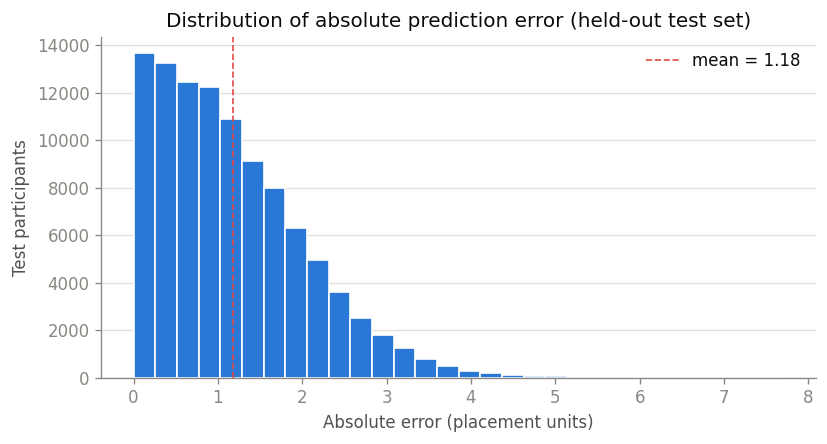

Share of predictions within 1 placement of the truth: 49.3%
Share of predictions off by more than 3 placements:   3.8%


In [39]:
test_errors = test_df.assign(
    pred=pred_test,
    abs_error=np.abs(test_df["placement"].values - pred_test),
    signed_error=pred_test - test_df["placement"].values,  # positive = model predicted worse than reality
)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(test_errors["abs_error"], bins=30, color=COLOR_BLUE, edgecolor="white")
ax.axvline(test_errors["abs_error"].mean(), color=COLOR_RED, linestyle="--", linewidth=1,
           label=f"mean = {test_errors['abs_error'].mean():.2f}")
ax.set_xlabel("Absolute error (placement units)")
ax.set_ylabel("Test participants")
ax.set_title("Distribution of absolute prediction error (held-out test set)")
ax.legend(frameon=False)
ax.grid(axis="y")
plt.tight_layout()
plt.show()

print(f"Share of predictions within 1 placement of the truth: {(test_errors['abs_error'] <= 1).mean():.1%}")
print(f"Share of predictions off by more than 3 placements:   {(test_errors['abs_error'] > 3).mean():.1%}")

### 13.2 Error by rank tier and by patch

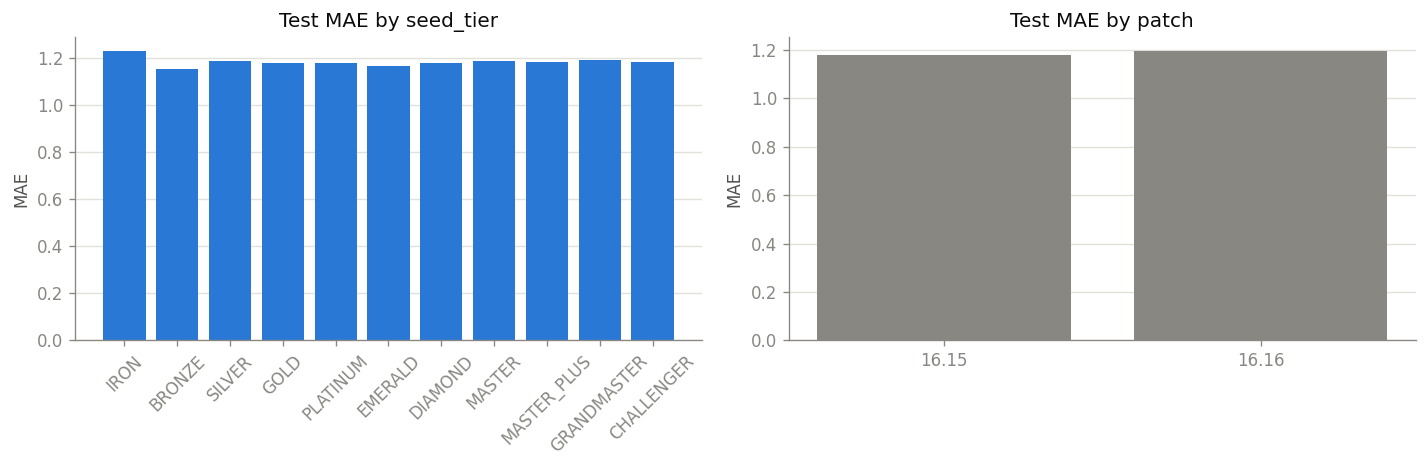

MAE by tier (n = sample size, small tiers are noisy):
              mean  count
seed_tier                
IRON         1.229    375
BRONZE       1.152    753
SILVER       1.187   2735
GOLD         1.178   6979
PLATINUM     1.178  11904
EMERALD      1.165  15064
DIAMOND      1.180  15808
MASTER       1.186  20024
MASTER_PLUS  1.184  16136
GRANDMASTER  1.193  10048
CHALLENGER   1.184   2376

MAE by patch:
        mean  count
patch              
16.15  1.178  85800
16.16  1.194  16402


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

mae_by_tier = test_errors.groupby("seed_tier")["abs_error"].agg(["mean", "count"])
mae_by_tier = mae_by_tier.reindex([t for t in TIER_ORDER if t in mae_by_tier.index]).dropna()
axes[0].bar(mae_by_tier.index, mae_by_tier["mean"], color=COLOR_BLUE)
axes[0].set_title("Test MAE by seed_tier")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y")

mae_by_patch = test_errors.groupby("patch")["abs_error"].agg(["mean", "count"]).sort_index()
axes[1].bar(mae_by_patch.index, mae_by_patch["mean"], color=COLOR_MUTED)
axes[1].set_title("Test MAE by patch")
axes[1].set_ylabel("MAE")
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

print("MAE by tier (n = sample size, small tiers are noisy):")
print(mae_by_tier.round(3).to_string())
print("\nMAE by patch:")
print(mae_by_patch.round(3).to_string())

### 13.3 Error by archetype and by contest level

Merging predictions with the archetype/contest labels from Sections 5-6 (joined on
`participant_id`) checks whether error concentrates in specific comps or contest situations, rather
than being spread evenly.

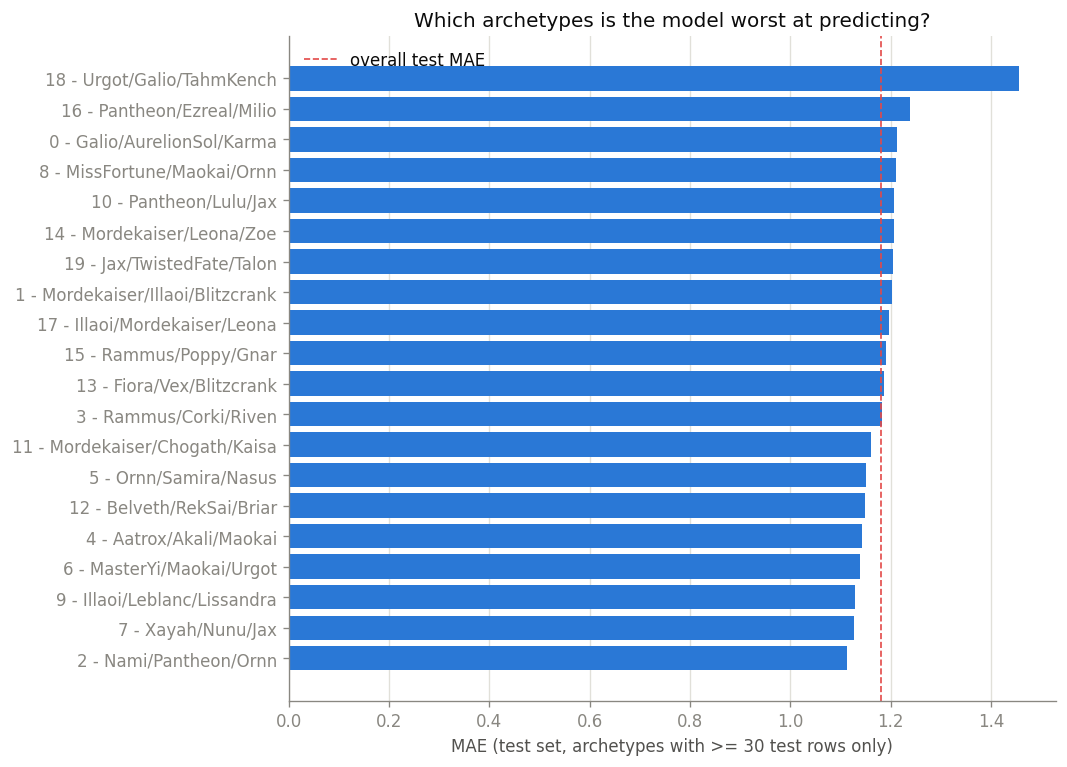

,n,mae,avg_signed_error
18 - Urgot/Galio/TahmKench,3949,1.456,0.392
16 - Pantheon/Ezreal/Milio,4039,1.238,0.246
0 - Galio/AurelionSol/Karma,5039,1.212,-0.057
8 - MissFortune/Maokai/Ornn,4440,1.211,0.117
10 - Pantheon/Lulu/Jax,2727,1.207,0.182
14 - Mordekaiser/Leona/Zoe,7916,1.205,-0.004
19 - Jax/TwistedFate/Talon,2997,1.205,0.253
1 - Mordekaiser/Illaoi/Blitzcrank,2580,1.202,-0.164
17 - Illaoi/Mordekaiser/Leona,4224,1.196,0.010
15 - Rammus/Poppy/Gnar,4733,1.190,0.061


In [41]:
error_with_archetype = test_errors.merge(
    contest_df[["participant_id", "archetype_cluster", "contest_bucket"]],
    on="participant_id", how="left",
)

mae_by_archetype = error_with_archetype.groupby("archetype_cluster").agg(
    n=("participant_id", "count"), mae=("abs_error", "mean"), avg_signed_error=("signed_error", "mean"),
)
mae_by_archetype = mae_by_archetype[mae_by_archetype["n"] >= 30]  # drop archetypes too rare in the test set to trust
mae_by_archetype.index = [short_board_label(cid) for cid in mae_by_archetype.index]
mae_by_archetype = mae_by_archetype.sort_values("mae", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(mae_by_archetype.index[::-1], mae_by_archetype["mae"][::-1], color=COLOR_BLUE)
ax.axvline(test_errors["abs_error"].mean(), color=COLOR_RED, linestyle="--", linewidth=1,
           label="overall test MAE")
ax.set_xlabel("MAE (test set, archetypes with >= 30 test rows only)")
ax.set_title("Which archetypes is the model worst at predicting?")
ax.legend(frameon=False)
ax.grid(axis="x")
plt.tight_layout()
plt.show()

mae_by_archetype.round(3)

In [42]:
mae_by_contest = error_with_archetype.groupby("contest_bucket")["abs_error"].agg(mean="mean", std="std", n="count")
mae_by_contest["ci95"] = 1.96 * mae_by_contest["std"] / np.sqrt(mae_by_contest["n"])
mae_by_contest = mae_by_contest.reindex(["0 (uncontested)", "1 other", "2+ others"])
mae_by_contest[["mean", "ci95", "n"]]


,mean,ci95,n
contest_bucket,,,
0 (uncontested),1.187623,0.006558,69784
1 other,1.171048,0.010351,27282
2+ others,1.137215,0.022917,5136


Error is clearly **not** uniform across archetypes, the worst-predicted archetypes run a noticeably
higher MAE than the overall test average, and (as Section 13.4 shows concretely) the single worst
individual errors concentrate heavily in one specific archetype.

The contest-level breakdown holds a genuine surprise, worth reporting exactly as found rather than
forced into the hypothesis that motivated it: MAE is **lowest**, not highest, for heavily-contested
boards (2+ others), and highest for uncontested ones. This is the *opposite* of "the model struggles
most where outcomes are most relative to the lobby." With 95% CIs attached: the 1-other vs. 2+-others
gap is clearly real (their CIs don't overlap at all), the uncontested vs. 1-other gap is a close call
(their intervals just barely touch), but the two extremes, uncontested vs. 2+ others, are unambiguously
separated. So this isn't a coin-flip pattern dressed up as a finding; contested boards genuinely are
easier to predict. A more plausible reading: heavy contest (Section 6) already pulls average placement
down toward a narrower, more predictable band, several players converging on the same well-known,
popular archetype is itself informative, and popular archetypes are, by definition, the ones the model
has seen the most training examples of. Rare, uncontested boards are more likely to be unusual comps
with less training signal behind them, which is a more mundane "less data -> more error" explanation
than a lobby-awareness gap. This is a useful reminder that a plausible-sounding hypothesis (mine, going
into this section) still needs to be checked against the actual numbers rather than assumed.


### 13.4 Worst individual predictions

A look at a handful of concrete cases the model missed most badly, not to explain every one, but to
check whether they look like noise (odd one-off boards, small-sample tiers) or a systematic pattern
worth flagging.

In [43]:
worst_cases = error_with_archetype.sort_values("abs_error", ascending=False).head(10)
worst_cases[["participant_id", "seed_tier", "patch", "archetype_cluster", "contest_bucket",
             "placement", "pred", "abs_error"]].assign(
    pred_raw=lambda d: d["pred"].round(2),
    pred_clipped=lambda d: np.clip(d["pred"], 1, 8).round(2),
    archetype_cluster=lambda d: d["archetype_cluster"].map(
        lambda cid: short_board_label(cid) if pd.notna(cid) else "n/a"
    ),
).drop(columns="pred")


,participant_id,seed_tier,patch,archetype_cluster,contest_bucket,placement,abs_error,pred_raw,pred_clipped
101087,272063,SILVER,16.15,18 - Urgot/Galio/TahmKench,1 other,1,7.705380,8.71,8.0
25716,45399,EMERALD,16.15,18 - Urgot/Galio/TahmKench,0 (uncontested),2,7.526573,9.53,8.0
42056,92058,GRANDMASTER,16.15,18 - Urgot/Galio/TahmKench,0 (uncontested),2,7.497723,9.50,8.0
61648,126426,DIAMOND,16.15,18 - Urgot/Galio/TahmKench,0 (uncontested),2,7.473089,9.47,8.0
43843,93965,MASTER,16.15,18 - Urgot/Galio/TahmKench,0 (uncontested),2,7.470125,9.47,8.0
64237,132591,DIAMOND,16.15,5 - Ornn/Samira/Nasus,0 (uncontested),2,7.439939,9.44,8.0
67318,144248,DIAMOND,16.16,18 - Urgot/Galio/TahmKench,0 (uncontested),2,7.439939,9.44,8.0
2118,3687,MASTER_PLUS,16.15,18 - Urgot/Galio/TahmKench,1 other,2,7.424225,9.42,8.0
48928,100978,MASTER,16.16,18 - Urgot/Galio/TahmKench,1 other,2,7.409524,9.41,8.0
76722,171748,EMERALD,16.15,18 - Urgot/Galio/TahmKench,2+ others,2,7.397875,9.40,8.0


This is not sample-size noise. The single worst errors are dominated by one specific archetype,
**Urgot/Galio/TahmKench (cluster 18)**, the same archetype flagged back in Section 5.3 as one of the
weaker comps overall (avg. placement 4.768, second-worst of the 20 clusters), and in Section 5.4 as
more popular in LOW tiers than HIGH (pick-rate gap -0.054) despite performing *better* when it is
played in HIGH, its top-4 rate is 0.483 in HIGH vs. 0.450 in LOW. 9 of the 10 worst individual
predictions belong to it; every one of those is a participant who **actually placed 1st or 2nd** with
that archetype, a genuinely great result the model still predicted close to last place. `pred_raw`
shows the model's unclipped output (9.4-9.5, past the valid 1-8 range, since regression doesn't
enforce it); `pred_clipped` shows what a deployed system would actually report after clamping to
[1, 8], and it's **8 for every single one of these ten cases**. Clipping doesn't rescue the
prediction at all: even capped at the best answer the model's raw score is compatible with, it still
lands on "dead last," the single worst possible call, for ten boards that finished 1st or 2nd. Spread
across several different tiers and both held-out patches, so it isn't a small-sample artifact either.
Section 13.3's aggregate number for this archetype tells the same story less dramatically: MAE 1.456
against an overall test MAE of 1.181, the single worst-predicted archetype by a clear margin (the
runner-up sits at 1.238).

**Reading this:** the model has learned, correctly on average, that this archetype usually performs
poorly, but that learned prior is strong enough that it can't recognize the rarer, well-executed
version of the same comp that actually wins. This is a coherent, specific failure mode rather than
random noise: a feature set built entirely from the *final* board has no way to distinguish "this comp
usually loses because it's structurally weak" from "this specific game, someone found a way to make it
work", exactly the execution/timing/context gap flagged as an unavoidable ceiling back in Section 10.2,
now pinned down to a concrete, reproducible example instead of stated only in the abstract.


## 14. Conclusions

### Answers to the research questions

**1. Can final board composition alone predict placement meaningfully better than a naive
baseline?** Yes. The time-based test MAE (Section 10) sits well below the baseline of always
predicting the mean, and top-4 accuracy is well above the 50% no-skill reference: a real, usable
signal, though far from perfect. That's consistent with the fact that a static final-board snapshot
cannot see matchups, positioning, execution, or augments.

**2. Which features matter most, and in which direction?** SHAP (Section 12) shows specific
high-star champions and specific key items dominate over individual traits taken alone; composition
*identity* (Section 5) matters more than any single piece. `gold_left` matters too, without a single
consistent direction: its mean SHAP effect is nearly directionless despite ranking 2nd by magnitude,
most plausibly proxying board weakness at one end of its range rather than acting as one direct
lever players should pull.

**3. Is board strength in TFT relative, shaped by lobby contest?** Yes, clearly (Section 6):
average placement worsens monotonically as more players in the same lobby share an archetype, an
effect that holds (with varying strength) across most archetypes. As stressed in Section 6.4,
though, this is a robust association, not a proven causal effect size, given the lack of
randomization in who plays what.

**4. Does the model generalize across patches, given TFT's frequent rebalancing?** Better than
expected going in: Section 11's random-split-vs-time-split comparison came out close (test MAE
1.173 vs. 1.181), so drift is mild over this specific 2-patch horizon. The per-patch MAE curve
traces a shallow U-shape, and with 95% CIs attached (Section 11.4) most single-patch-to-patch steps
aren't reliably distinguishable from noise, but the extremes are (16.13, the best-fit training
patch, vs. 16.16, the worst and furthest from training, don't overlap at all), so the shape itself
is real even though the total spread (~0.055 MAE) is modest. That distinction matters: mild,
statistically real drift now is not evidence the model would stay accurate over a much longer time
horizon or a more disruptive patch than any seen in this data.

**5. Where does the model fail?** Section 13 shows error is not uniform, but not in the way the
contest hypothesis predicted, MAE is actually **lowest** for heavily-contested boards and highest
for uncontested, rare ones (more training examples, not more lobby-awareness, is the likely
explanation; the CIs confirm the 1-other vs. 2+-others gap and the two extremes are real, while
uncontested vs. 1-other is a closer call). The clearer, well-evidenced failure mode is
archetype-specific and directional: the model has learned that the Urgot/Galio/TahmKench archetype
(Section 5.3-5.4) usually performs poorly, and that prior is strong enough to badly under-predict the
rarer games where the same comp actually wins (Section 13.4), a genuine blind spot rooted in only
ever seeing the *final* board, not how the game got there. Clipping the model's output to the valid
1-8 range doesn't fix this: for all ten of the worst individual errors, the clipped prediction is
still "8th place," the single worst call available, for boards that finished 1st or 2nd.

### Key limitations (carried through the whole notebook, not just here)

- `seed_tier` is a **match-level** label copied from one seed player, not a verified
  per-participant rank (Section 2). Tier-based conclusions are approximate for that reason.
- The dataset **over-represents recent patches for low-activity tiers** (Section 3.5), a
  structural sampling artifact of the Riot API's "N most recent matches" limit that collecting more
  data the same way wouldn't fix.
- **~2.1% of raw participant rows are AI-controlled bots** (Section 3.1), concentrated in Iron
  through Gold, that Riot fills into low-population lobbies. This one measurably distorted
  conclusions rather than just formatting, so it's excluded at the source
  (`src/features/build_feature_matrix.py`, `src/analysis/tier_comparison.py`) instead of only
  flagged like the patch dtype bug below.
  measurably distorted conclusions (the low-tier average-placement chart in Section 4.2, the LOW/HIGH
  archetype pick-rate gap in Section 5.4) rather than just formatting, so it's excluded at the source
  (`src/features/build_feature_matrix.py`, `src/analysis/tier_comparison.py`) rather than only flagged.
- **Augments are entirely unavailable** in this dataset (Section 3.4), despite being a major TFT
  mechanic. Any model built from this data is necessarily blind to them.
- The archetype clustering has **low silhouette scores** (Section 5.2): useful, interpretable
  groupings, not a claim of sharply separated natural categories. Cluster IDs are canonicalized by
  performance rank so they at least stay self-consistent within one fit, but a rerun on different
  data can still converge to a different set of clusters — the numbering is stable; the underlying
  grouping isn't guaranteed to be.
- The contest analysis and the tier SHAP breakdown are both **observational**, not causal
  (Sections 6.4, 12.4). Read them as associations, not as levers with a fixed, transferable effect
  size.
- Confidence intervals throughout this notebook (Sections 11.4, 12.2, 13.3) are helpful for
  telling real patterns from noise at *reasonable* sample sizes, but they can't rescue a genuinely
  tiny one: normal-approximation and bootstrap CIs agreed with each other for IRON (`n=5`) and
  BRONZE (`n=18`) and both were still wrong to trust, because resampling from 5-18 points can't
  manufacture variability neither method's input data contained in the first place.
- A data-type bug was found (Section 3.6, patch `"16.10"` silently becoming `16.1`) that turned
  out not to affect the split or the model's predictive performance, but did corrupt chronological
  sorting/labeling wherever the feature matrix CSV is read without an explicit `dtype` hint, fixed
  locally in this notebook, and flagged (rather than silently patched) in `src/`.

